# Bank Marketing: Sequential vs Functional ANN

**Original coursework experiment** on UCI `bank-full.csv`. This notebook contains the original Bank Marketing code cells, saved outputs, and explanatory markdown extracted from `main.ipynb`. Unrelated answers to other coursework questions were excluded. The full mixed-topic original is supplied separately in `PRIVATE-BACKUP-original_main.ipynb` outside the GitHub repository folder and is not published. One incomplete `tensorflow.keras.optimizers` import is fixed in this working copy (`Adam`) so that code cells parse.

**Evaluation scope:** metrics include `duration` (post-call information), so they are not pre-call lead-scoring estimates.


# SOAL NOMOR 2

In [ ]:
import os
import json
import random
import numpy as np
import pandas as pd
import tensorflow as tf
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, RobustScaler
from sklearn.impute import SimpleImputer
from sklearn.metrics import (
    accuracy_score, classification_report, confusion_matrix,
    roc_auc_score, precision_score, recall_score, f1_score
)
from sklearn.utils.class_weight import compute_class_weight

from tensorflow.keras.models import Sequential, Model
from tensorflow.keras.layers import (
    Input, Dense, Dropout, BatchNormalization
)
from tensorflow.keras.regularizers import l2
from tensorflow.keras.callbacks import (
    EarlyStopping, ModelCheckpoint, CSVLogger, ReduceLROnPlateau
)
from tensorflow.keras.optimizers import Adam
from sklearn.metrics import roc_curve, auc

# A. Exploratory Data Analysis

In [277]:
import pandas as pd

df = pd.read_csv('bank-full.csv', sep=';')

df

,age,job,marital,education,default,balance,housing,loan,contact,day,month,duration,campaign,pdays,previous,poutcome,y
0,58,management,married,tertiary,no,2143,yes,no,unknown,5,may,261,1,-1,0,unknown,no
1,44,technician,single,secondary,no,29,yes,no,unknown,5,may,151,1,-1,0,unknown,no
2,33,entrepreneur,married,secondary,no,2,yes,yes,unknown,5,may,76,1,-1,0,unknown,no
3,47,blue-collar,married,unknown,no,1506,yes,no,unknown,5,may,92,1,-1,0,unknown,no
4,33,unknown,single,unknown,no,1,no,no,unknown,5,may,198,1,-1,0,unknown,no
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
45206,51,technician,married,tertiary,no,825,no,no,cellular,17,nov,977,3,-1,0,unknown,yes
45207,71,retired,divorced,primary,no,1729,no,no,cellular,17,nov,456,2,-1,0,unknown,yes
45208,72,retired,married,secondary,no,5715,no,no,cellular,17,nov,1127,5,184,3,success,yes
45209,57,blue-collar,married,secondary,no,668,no,no,telephone,17,nov,508,4,-1,0,unknown,no


In [278]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 45211 entries, 0 to 45210
Data columns (total 17 columns):
 #   Column     Non-Null Count  Dtype 
---  ------     --------------  ----- 
 0   age        45211 non-null  int64 
 1   job        45211 non-null  object
 2   marital    45211 non-null  object
 3   education  45211 non-null  object
 4   default    45211 non-null  object
 5   balance    45211 non-null  int64 
 6   housing    45211 non-null  object
 7   loan       45211 non-null  object
 8   contact    45211 non-null  object
 9   day        45211 non-null  int64 
 10  month      45211 non-null  object
 11  duration   45211 non-null  int64 
 12  campaign   45211 non-null  int64 
 13  pdays      45211 non-null  int64 
 14  previous   45211 non-null  int64 
 15  poutcome   45211 non-null  object
 16  y          45211 non-null  object
dtypes: int64(7), object(10)
memory usage: 5.9+ MB


Berdasarkan hasil `df.info()`, dataset memiliki **45.211 baris data** dan **17 kolom fitur**. Dataset ini terdiri dari dua tipe data utama yaitu **numerical (int64)** dan **categorical (object)**.

### Struktur Data

Dataset memiliki:
- **7 kolom numerik**
- **10 kolom kategorikal**

Kolom numerik meliputi:
- `age`
- `balance`
- `day`
- `duration`
- `campaign`
- `pdays`
- `previous`

Kolom kategorikal meliputi:
- `job`
- `marital`
- `education`
- `default`
- `housing`
- `loan`
- `contact`
- `month`
- `poutcome`
- `y` (target)

### Missing Values

Semua kolom memiliki **Non-Null Count sebesar 45.211**, yang menunjukkan bahwa **dataset tidak memiliki missing value (NaN)**. Hal ini menunjukkan bahwa kualitas data cukup baik untuk langsung digunakan dalam proses analisis dan pemodelan.

### Target Variable

Kolom `y` merupakan **target variable** yang menunjukkan apakah nasabah menerima penawaran deposito dari kampanye marketing bank.

Nilai pada kolom `y` berupa:
- `yes` → nasabah menerima penawaran
- `no` → nasabah tidak menerima penawaran

### Insight Awal

Beberapa insight awal yang dapat diperoleh dari struktur dataset ini adalah:

1. Dataset memiliki jumlah data yang cukup besar sehingga cocok digunakan untuk pelatihan model machine learning maupun deep learning.
2. Banyak fitur yang bertipe kategorikal sehingga perlu dilakukan **encoding** sebelum digunakan dalam model ANN.
3. Fitur numerik seperti `age`, `balance`, dan `duration` kemungkinan perlu dilakukan **normalisasi atau standardisasi** agar model neural network dapat belajar dengan lebih stabil.
4. Tidak adanya missing value mempermudah tahap preprocessing karena tidak perlu melakukan imputasi data.

## 1. Kolom Numerik

In [279]:
df.describe()

,age,balance,day,duration,campaign,pdays,previous
count,45211.000000,45211.000000,45211.000000,45211.000000,45211.000000,45211.000000,45211.000000
mean,40.936210,1362.272058,15.806419,258.163080,2.763841,40.197828,0.580323
std,10.618762,3044.765829,8.322476,257.527812,3.098021,100.128746,2.303441
min,18.000000,-8019.000000,1.000000,0.000000,1.000000,-1.000000,0.000000
25%,33.000000,72.000000,8.000000,103.000000,1.000000,-1.000000,0.000000
50%,39.000000,448.000000,16.000000,180.000000,2.000000,-1.000000,0.000000
75%,48.000000,1428.000000,21.000000,319.000000,3.000000,-1.000000,0.000000
max,95.000000,102127.000000,31.000000,4918.000000,63.000000,871.000000,275.000000


Berdasarkan hasil statistik deskriptif pada kolom numerik (`age`, `balance`, `day`, `duration`, `campaign`, `pdays`, `previous`), terdapat beberapa insight penting mengenai karakteristik dataset.

### Distribusi Usia Nasabah

Rata-rata usia nasabah adalah sekitar **40,9 tahun** dengan standar deviasi **10,6**. Usia minimum dalam dataset adalah **18 tahun**, sedangkan usia maksimum mencapai **95 tahun**. Nilai median usia adalah **39 tahun**, yang menunjukkan bahwa sebagian besar nasabah berada pada rentang usia produktif.

### Kondisi Saldo Rekening Nasabah

Kolom `balance` menunjukkan rata-rata saldo rekening nasabah sekitar **1362** dengan standar deviasi yang cukup besar yaitu **3044**, yang menunjukkan variasi saldo yang tinggi antar nasabah. Nilai minimum saldo bahkan mencapai **-8019**, yang kemungkinan menunjukkan adanya nasabah dengan saldo negatif atau overdraft. Sementara itu, nilai maksimum mencapai **102127**, yang menunjukkan adanya beberapa nasabah dengan saldo yang sangat tinggi.

### Waktu Kontak dalam Kampanye

Kolom `day` menunjukkan bahwa kontak dengan nasabah terjadi sepanjang bulan, dengan rata-rata pada hari **ke-15 hingga ke-16**. Nilai minimum adalah **hari ke-1** dan maksimum **hari ke-31**, yang menunjukkan bahwa kampanye marketing dilakukan secara merata selama satu bulan.

### Durasi Panggilan

Durasi panggilan (`duration`) memiliki rata-rata sekitar **258 detik** dengan median **180 detik**. Namun terdapat variasi yang cukup besar karena nilai maksimum mencapai **4918 detik**, yang menunjukkan bahwa beberapa panggilan berlangsung sangat lama dibandingkan rata-rata.

### Frekuensi Kontak Selama Kampanye

Kolom `campaign` menunjukkan jumlah kontak yang dilakukan kepada nasabah selama satu kampanye marketing. Rata-rata jumlah kontak adalah sekitar **2,7 kali** dengan median **2 kali**. Namun nilai maksimum mencapai **63 kali**, yang menunjukkan adanya beberapa nasabah yang dihubungi berkali-kali.

### Riwayat Kontak Sebelumnya

Kolom `pdays` menunjukkan jumlah hari sejak nasabah terakhir kali dihubungi dalam kampanye sebelumnya. Nilai median adalah **-1**, yang biasanya menandakan bahwa sebagian besar nasabah **belum pernah dihubungi sebelumnya**. Hal ini menunjukkan bahwa banyak nasabah yang merupakan target baru dalam kampanye marketing.

Kolom `previous` menunjukkan jumlah kontak yang dilakukan sebelum kampanye saat ini. Rata-rata jumlah kontak sebelumnya hanya sekitar **0,58**, dengan median **0**, yang memperkuat indikasi bahwa sebagian besar nasabah belum pernah dihubungi sebelumnya.

### Kesimpulan Awal

Secara umum, dataset menunjukkan bahwa sebagian besar nasabah berada pada usia produktif, memiliki variasi saldo yang cukup besar, serta sebagian besar belum pernah dihubungi dalam kampanye sebelumnya. Informasi ini dapat membantu model machine learning dalam mempelajari pola perilaku nasabah dalam merespon kampanye marketing bank.

## 2. Kolom Kategorik

In [280]:
df.describe(include='object')

,job,marital,education,default,housing,loan,contact,month,poutcome,y
count,45211,45211,45211,45211,45211,45211,45211,45211,45211,45211
unique,12,3,4,2,2,2,3,12,4,2
top,blue-collar,married,secondary,no,yes,no,cellular,may,unknown,no
freq,9732,27214,23202,44396,25130,37967,29285,13766,36959,39922


### Insight Variabel Kategorikal

Berdasarkan hasil analisis statistik deskriptif pada variabel kategorikal, dataset memiliki beberapa karakteristik penting terkait profil nasabah dan hasil kampanye pemasaran bank.

### Jenis Pekerjaan (job)

Kolom `job` memiliki **12 kategori pekerjaan berbeda**, dengan kategori yang paling sering muncul adalah **blue-collar** sebanyak **9.732 data**. Hal ini menunjukkan bahwa sebagian besar nasabah dalam dataset berasal dari kelompok pekerja manual atau pekerja lapangan.

### Status Pernikahan (marital)

Kolom `marital` memiliki **3 kategori status pernikahan**, yaitu `married`, `single`, dan `divorced`. Status yang paling dominan adalah **married** dengan **27.214 nasabah**, yang menunjukkan bahwa mayoritas nasabah bank dalam dataset sudah menikah.

### Tingkat Pendidikan (education)

Variabel `education` memiliki **4 kategori pendidikan**, dengan kategori yang paling sering muncul adalah **secondary** sebanyak **23.202 data**. Hal ini menunjukkan bahwa sebagian besar nasabah memiliki tingkat pendidikan menengah.

### Riwayat Kredit Macet (default)

Kolom `default` menunjukkan apakah nasabah memiliki riwayat kredit macet. Sebagian besar nasabah memiliki nilai **no (44.396 data)**, yang berarti mayoritas nasabah tidak memiliki riwayat kredit macet.

### Kepemilikan Pinjaman Rumah (housing)

Variabel `housing` menunjukkan apakah nasabah memiliki pinjaman rumah. Sebanyak **25.130 nasabah memiliki housing loan**, yang menunjukkan bahwa lebih dari setengah nasabah memiliki pinjaman rumah.

### Kepemilikan Pinjaman Pribadi (loan)

Pada kolom `loan`, sebagian besar nasabah **tidak memiliki pinjaman pribadi**, yaitu sebanyak **37.967 data**. Hal ini menunjukkan bahwa mayoritas nasabah tidak memiliki kewajiban pinjaman tambahan selain kemungkinan pinjaman rumah.

### Jenis Kontak (contact)

Kolom `contact` menunjukkan metode komunikasi yang digunakan untuk menghubungi nasabah. Metode yang paling sering digunakan adalah **cellular** sebanyak **29.285 data**, yang menunjukkan bahwa sebagian besar kampanye pemasaran dilakukan melalui telepon seluler.

### Bulan Kontak (month)

Kolom `month` memiliki **12 kategori bulan**, dengan bulan yang paling sering digunakan untuk kampanye adalah **May** sebanyak **13.766 kontak**. Hal ini menunjukkan bahwa aktivitas pemasaran bank paling banyak dilakukan pada bulan tersebut.

### Hasil Kampanye Sebelumnya (poutcome)

Variabel `poutcome` menunjukkan hasil dari kampanye pemasaran sebelumnya. Nilai yang paling dominan adalah **unknown** dengan **36.959 data**, yang mengindikasikan bahwa sebagian besar nasabah belum pernah dihubungi atau tidak memiliki catatan hasil kampanye sebelumnya.

### Target Variabel (y)

Kolom `y` merupakan variabel target yang menunjukkan apakah nasabah menerima tawaran deposito. Nilai yang paling sering muncul adalah **no** sebanyak **39.922 data**, yang menunjukkan bahwa sebagian besar nasabah **tidak menerima tawaran deposito** dari kampanye pemasaran bank.

### Kesimpulan Awal

Dari analisis variabel kategorikal, dapat dilihat bahwa mayoritas nasabah dalam dataset adalah pekerja blue-collar, berstatus menikah, memiliki pendidikan menengah, serta tidak memiliki riwayat kredit macet. Selain itu, sebagian besar nasabah tidak menerima tawaran deposito, yang menunjukkan adanya **ketidakseimbangan kelas (class imbalance)** pada variabel target.

## 3. Tipe Data

Berdasarkan hasil pemeriksaan struktur dataset menggunakan `df.info()`, dataset memiliki total **45.211 baris data** dengan **17 kolom**. Tipe data yang terdapat dalam dataset terdiri dari dua jenis utama, yaitu **numerical (int64)** dan **categorical (object)**.

Kolom numerik dalam dataset adalah:
- `age`
- `balance`
- `day`
- `duration`
- `campaign`
- `pdays`
- `previous`

Kolom-kolom tersebut sudah bertipe **int64**, sehingga tidak memerlukan perubahan tipe data untuk analisis numerik. Namun, beberapa fitur numerik kemungkinan perlu dilakukan **normalisasi atau standardisasi** sebelum digunakan dalam model Artificial Neural Network (ANN) agar proses training menjadi lebih stabil.

Sementara itu, terdapat beberapa kolom dengan tipe data **object** yang merupakan variabel kategorikal, yaitu:
- `job`
- `marital`
- `education`
- `default`
- `housing`
- `loan`
- `contact`
- `month`
- `poutcome`
- `y`

Kolom-kolom tersebut tidak dapat langsung digunakan dalam model ANN karena neural network hanya dapat memproses data numerik. Oleh karena itu, variabel kategorikal perlu diubah menjadi bentuk numerik menggunakan teknik encoding seperti **Label Encoding** atau **One-Hot Encoding**.

Selain itu, kolom `y` merupakan **target variable** dengan nilai `yes` dan `no`. Kolom ini perlu dikonversi menjadi nilai numerik, misalnya:
- `yes` → 1  
- `no` → 0  

Secara keseluruhan, tipe data pada dataset sudah cukup sesuai, namun diperlukan proses **encoding pada variabel kategorikal** dan kemungkinan **normalisasi pada variabel numerik** sebelum dataset digunakan dalam pelatihan model ANN.

## 4. Visualisasi

### a. Age vs Deposit Outcome

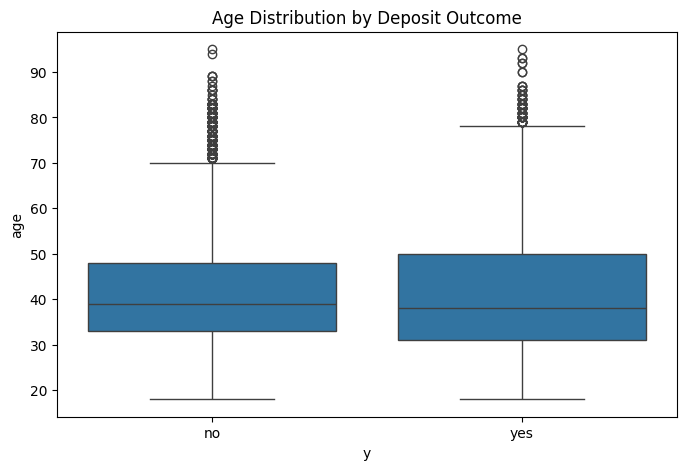

In [281]:
plt.figure(figsize=(8,5))
sns.boxplot(x='y', y='age', data=df)
plt.title("Age Distribution by Deposit Outcome")
plt.show()

Visualisasi boxplot menunjukkan distribusi usia nasabah berdasarkan keputusan mereka dalam menerima tawaran deposito (`y`).

Dari grafik terlihat bahwa distribusi usia antara nasabah yang **menerima deposito (yes)** dan yang **tidak menerima deposito (no)** memiliki pola yang relatif mirip. Median usia pada kedua kelompok berada di kisaran **akhir 30-an hingga awal 40-an**, yang menunjukkan bahwa mayoritas nasabah dalam dataset berada pada rentang usia produktif.

Namun, terlihat bahwa kelompok nasabah yang menerima deposito (`yes`) memiliki **rentang usia yang sedikit lebih lebar** serta nilai maksimum yang sedikit lebih tinggi dibandingkan kelompok `no`. Hal ini mengindikasikan bahwa nasabah yang lebih tua mungkin memiliki kecenderungan sedikit lebih tinggi untuk menerima tawaran deposito.

Selain itu, terdapat beberapa **outlier usia yang cukup tinggi (di atas 80 tahun)** pada kedua kelompok, yang menunjukkan adanya sebagian kecil nasabah lanjut usia dalam dataset.

Secara keseluruhan, usia bukan merupakan faktor yang sangat membedakan antara nasabah yang menerima dan menolak deposito, karena distribusi kedua kelompok cukup mirip. Namun demikian, usia tetap dapat menjadi salah satu fitur yang membantu model dalam mempelajari pola keputusan nasabah.

### b. Balance vs Deposit Outcome

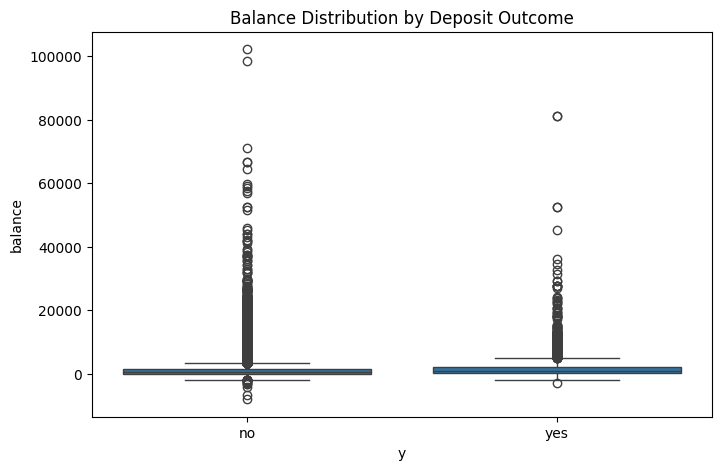

In [282]:
plt.figure(figsize=(8,5))
sns.boxplot(x='y', y='balance', data=df)
plt.title("Balance Distribution by Deposit Outcome")
plt.show()

Visualisasi boxplot menunjukkan distribusi saldo rekening (`balance`) nasabah berdasarkan keputusan mereka dalam menerima tawaran deposito (`y`).

Secara umum, terlihat bahwa distribusi saldo antara nasabah yang **menerima deposito (yes)** dan yang **tidak menerima deposito (no)** memiliki pola yang cukup mirip. Median saldo pada kedua kelompok berada di kisaran yang relatif rendah, yang menunjukkan bahwa sebagian besar nasabah memiliki saldo rekening yang tidak terlalu besar.

Namun demikian, terlihat bahwa kelompok nasabah yang menerima deposito (`yes`) memiliki **median saldo yang sedikit lebih tinggi** dibandingkan kelompok `no`. Hal ini mengindikasikan bahwa nasabah dengan saldo yang lebih besar cenderung memiliki kemungkinan yang lebih tinggi untuk menerima tawaran deposito.

Selain itu, terdapat banyak **outlier dengan saldo yang sangat tinggi** pada kedua kelompok, bahkan mencapai lebih dari **100.000**. Hal ini menunjukkan bahwa terdapat sebagian kecil nasabah dengan saldo yang jauh lebih besar dibandingkan mayoritas nasabah lainnya. Distribusi ini juga menunjukkan bahwa variabel `balance` memiliki **skewness yang tinggi** dan rentang nilai yang sangat lebar.

Secara keseluruhan, saldo rekening dapat menjadi salah satu fitur yang berpotensi berpengaruh terhadap keputusan nasabah dalam menerima produk deposito. Oleh karena itu, variabel `balance` dapat menjadi fitur penting yang digunakan dalam proses pelatihan model machine learning atau deep learning.

### c. Job vs Deposit Outcome

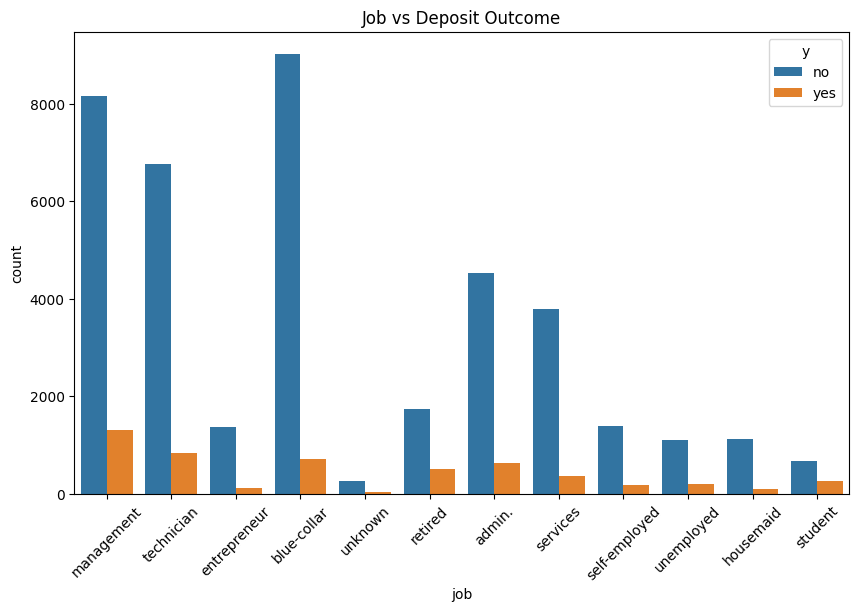

In [283]:
plt.figure(figsize=(10,6))
sns.countplot(x='job', hue='y', data=df)
plt.xticks(rotation=45)
plt.title("Job vs Deposit Outcome")
plt.show()

### d. Month vs Deposit Outcome

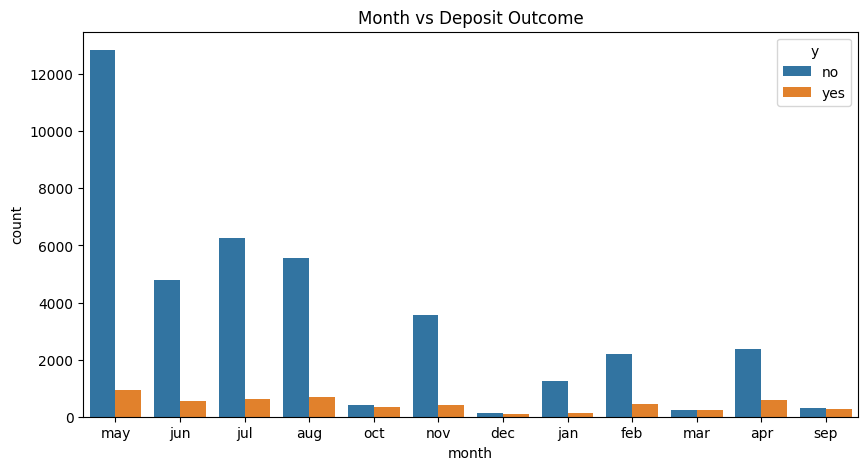

In [284]:
plt.figure(figsize=(10,5))
sns.countplot(x='month', hue='y', data=df)
plt.title("Month vs Deposit Outcome")
plt.show()

Visualisasi countplot menunjukkan distribusi jumlah nasabah yang dihubungi setiap bulan (`month`) serta hasil keputusan mereka dalam menerima tawaran deposito (`y`).

Dari grafik terlihat bahwa aktivitas kampanye pemasaran bank paling banyak dilakukan pada bulan **May**, dengan jumlah kontak yang jauh lebih tinggi dibandingkan bulan lainnya. Namun, meskipun jumlah kontak pada bulan May sangat besar, sebagian besar nasabah tetap **menolak tawaran deposito (`no`)**.

Beberapa bulan lain seperti **July, August, dan June** juga menunjukkan jumlah kontak yang cukup tinggi, namun pola yang sama masih terlihat, yaitu jumlah nasabah yang menolak tawaran tetap lebih besar dibandingkan yang menerima.

Menariknya, pada beberapa bulan seperti **March, April, dan September**, meskipun jumlah kontak lebih sedikit, proporsi nasabah yang menerima deposito terlihat relatif lebih tinggi dibandingkan bulan dengan jumlah kontak besar. Hal ini dapat mengindikasikan bahwa waktu pelaksanaan kampanye dapat mempengaruhi tingkat keberhasilan pemasaran.

Secara keseluruhan, variabel `month` dapat memberikan insight mengenai **musiman (seasonality)** dalam keberhasilan kampanye pemasaran bank. Informasi ini dapat membantu bank menentukan waktu yang lebih efektif untuk melakukan kampanye deposito di masa mendatang.

### e. Duration vs Deposit Outcome

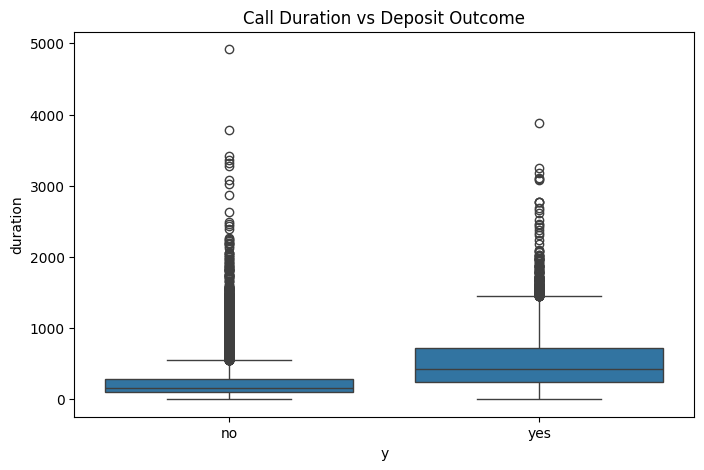

In [285]:
plt.figure(figsize=(8,5))
sns.boxplot(x='y', y='duration', data=df)
plt.title("Call Duration vs Deposit Outcome")
plt.show()

Visualisasi boxplot menunjukkan distribusi durasi panggilan telepon (`duration`) berdasarkan keputusan nasabah dalam menerima tawaran deposito (`y`).

Dari grafik terlihat perbedaan yang cukup jelas antara kedua kelompok. Nasabah yang **menerima tawaran deposito (`yes`)** cenderung memiliki **durasi panggilan yang lebih lama** dibandingkan nasabah yang menolak (`no`). Median durasi panggilan pada kelompok `yes` terlihat lebih tinggi dibandingkan kelompok `no`, yang menunjukkan bahwa percakapan yang lebih panjang kemungkinan memberikan kesempatan lebih besar bagi petugas pemasaran untuk menjelaskan produk secara lebih detail.

Sebaliknya, nasabah yang menolak tawaran deposito umumnya memiliki **durasi panggilan yang lebih pendek**, yang dapat mengindikasikan bahwa mereka kurang tertarik atau mengakhiri percakapan lebih cepat.

Selain itu, terdapat banyak **outlier dengan durasi panggilan yang sangat panjang** pada kedua kelompok, bahkan mencapai lebih dari **4000 detik**. Hal ini menunjukkan bahwa terdapat beberapa panggilan yang berlangsung jauh lebih lama dibandingkan mayoritas panggilan lainnya.

Secara keseluruhan, variabel `duration` tampak memiliki hubungan yang cukup kuat dengan keputusan nasabah dalam menerima deposito. Hal ini mengindikasikan bahwa durasi percakapan dapat menjadi salah satu fitur penting dalam memprediksi keberhasilan kampanye pemasaran bank.

### f. Housing Loan vs Deposit Outcome

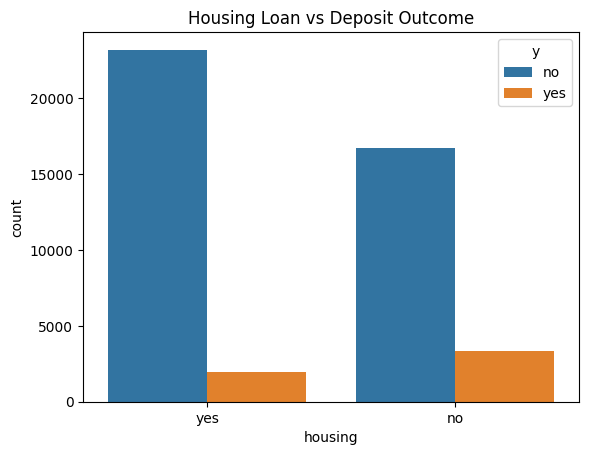

In [286]:
sns.countplot(x='housing', hue='y', data=df)
plt.title("Housing Loan vs Deposit Outcome")
plt.show()

Visualisasi countplot menunjukkan hubungan antara kepemilikan pinjaman rumah (`housing`) dengan keputusan nasabah dalam menerima tawaran deposito (`y`).

Dari grafik terlihat bahwa sebagian besar nasabah dalam dataset **memiliki housing loan (`yes`)**. Namun, pada kelompok ini jumlah nasabah yang **menolak tawaran deposito (`no`)** jauh lebih besar dibandingkan yang menerima.

Sebaliknya, pada nasabah yang **tidak memiliki housing loan (`no`)**, jumlah nasabah yang menerima deposito terlihat relatif lebih besar dibandingkan kelompok yang memiliki pinjaman rumah. Hal ini mengindikasikan bahwa nasabah yang tidak memiliki kewajiban pinjaman rumah mungkin memiliki **kondisi finansial yang lebih fleksibel** sehingga lebih memungkinkan untuk menyimpan dana dalam bentuk deposito.

Selain itu, meskipun jumlah nasabah dengan housing loan lebih banyak dalam dataset, tingkat keberhasilan kampanye pemasaran tampak lebih tinggi pada kelompok yang **tidak memiliki housing loan**.

Secara keseluruhan, variabel `housing` dapat memberikan insight mengenai kondisi finansial nasabah dan berpotensi menjadi fitur yang relevan dalam memprediksi kemungkinan nasabah menerima produk deposito yang ditawarkan oleh bank.

### g. Job vs Balance vs Deposit

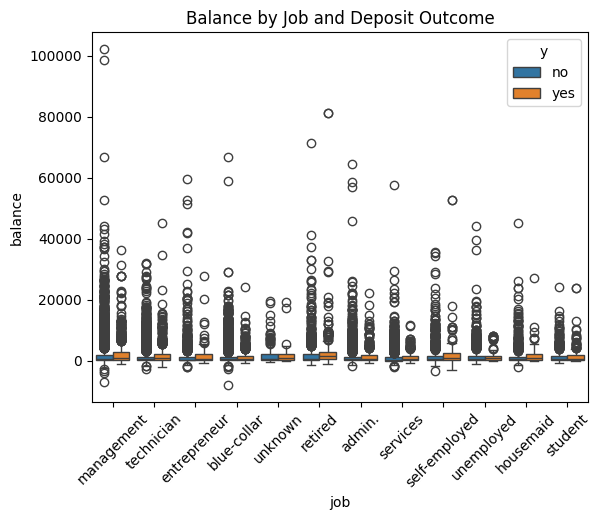

In [287]:
sns.boxplot(x='job', y='balance', hue='y', data=df)
plt.xticks(rotation=45)
plt.title("Balance by Job and Deposit Outcome")
plt.show()

Visualisasi boxplot menunjukkan distribusi saldo rekening (`balance`) pada setiap kategori pekerjaan (`job`) serta hubungannya dengan keputusan nasabah dalam menerima tawaran deposito (`y`).

Dari grafik terlihat bahwa terdapat variasi saldo yang cukup besar antar jenis pekerjaan. Beberapa kategori pekerjaan seperti **management, entrepreneur, dan retired** cenderung memiliki rentang saldo yang lebih tinggi dibandingkan kategori lainnya. Hal ini menunjukkan bahwa kelompok pekerjaan tersebut memiliki kondisi finansial yang relatif lebih baik.

Sebaliknya, kategori pekerjaan seperti **blue-collar, services, dan housemaid** cenderung memiliki distribusi saldo yang lebih rendah dan lebih terkonsentrasi di sekitar nilai kecil. Hal ini dapat mengindikasikan bahwa kelompok pekerjaan tersebut memiliki kapasitas finansial yang lebih terbatas.

Selain itu, terlihat bahwa nasabah yang menerima deposito (`yes`) umumnya memiliki saldo yang relatif lebih tinggi dibandingkan nasabah yang menolak (`no`) dalam beberapa kategori pekerjaan. Hal ini menunjukkan bahwa kombinasi antara **jenis pekerjaan dan tingkat saldo rekening** dapat memberikan informasi yang lebih kuat dalam memahami perilaku nasabah terhadap produk deposito.

Namun demikian, terdapat juga banyak **outlier dengan saldo sangat tinggi** pada berbagai kategori pekerjaan, yang menunjukkan adanya beberapa nasabah dengan saldo yang jauh lebih besar dibandingkan mayoritas lainnya.

Secara keseluruhan, interaksi antara variabel `job` dan `balance` dapat memberikan insight tambahan mengenai kondisi finansial nasabah dan berpotensi menjadi fitur penting dalam memprediksi keputusan nasabah dalam menerima tawaran deposito.

### h. Heatmap Korelasi Sebelum Data Prepocessing

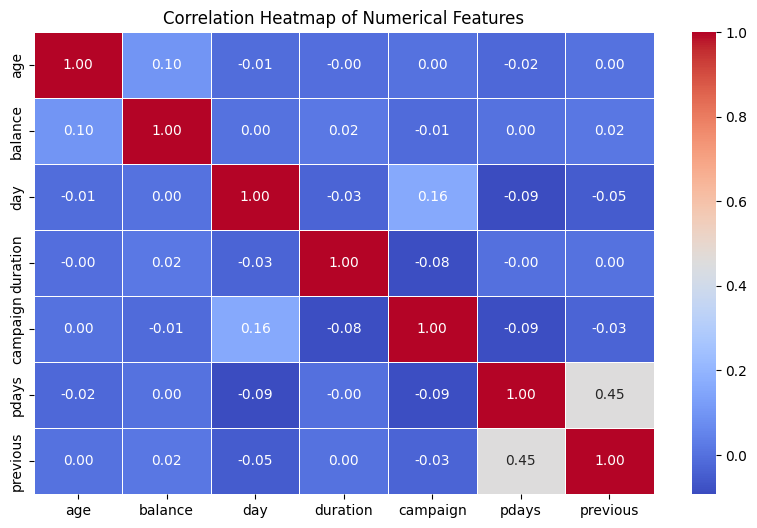

In [288]:
plt.figure(figsize=(10,6))

corr = df[['age','balance','day','duration','campaign','pdays','previous']].corr()

sns.heatmap(corr,
            annot=True,
            cmap='coolwarm',
            fmt=".2f",
            linewidths=0.5)

plt.title("Correlation Heatmap of Numerical Features")
plt.show()

Heatmap menunjukkan korelasi antara variabel numerik dalam dataset, yaitu `age`, `balance`, `day`, `duration`, `campaign`, `pdays`, dan `previous`.

Secara umum, sebagian besar variabel numerik memiliki **korelasi yang sangat rendah satu sama lain**, dengan nilai korelasi yang mendekati 0. Hal ini menunjukkan bahwa masing-masing fitur memberikan informasi yang relatif independen dan tidak memiliki hubungan linear yang kuat dengan fitur lainnya.

Salah satu hubungan yang paling terlihat adalah antara variabel **`pdays` dan `previous`** dengan nilai korelasi sekitar **0.45**, yang menunjukkan korelasi positif sedang. Hal ini masuk akal karena kedua variabel tersebut berkaitan dengan **riwayat kontak nasabah dalam kampanye pemasaran sebelumnya**.

Selain itu, terdapat korelasi kecil antara **`day` dan `campaign`** sekitar **0.16**, yang menunjukkan bahwa semakin lama periode kampanye berlangsung dalam satu bulan, jumlah kontak yang dilakukan kepada nasabah cenderung sedikit meningkat.

Variabel lain seperti **`age`, `balance`, dan `duration`** menunjukkan korelasi yang sangat kecil terhadap variabel lainnya. Hal ini mengindikasikan bahwa faktor-faktor tersebut kemungkinan memberikan kontribusi informasi yang berbeda dalam memprediksi keputusan nasabah.

Secara keseluruhan, tidak terdapat korelasi yang sangat tinggi antar variabel numerik dalam dataset. Hal ini menunjukkan bahwa risiko **multicollinearity** relatif rendah, sehingga fitur-fitur tersebut dapat digunakan bersama dalam model machine learning atau deep learning tanpa menimbulkan masalah redundansi informasi yang signifikan.

# B. Data Prepocessing

function untuk mengecek outlier

In [289]:
def detect_outliers_iqr(df, columns):
    
    outlier_rows = pd.DataFrame()

    for col in columns:
        Q1 = df[col].quantile(0.25)
        Q3 = df[col].quantile(0.75)
        IQR = Q3 - Q1

        lower_bound = Q1 - 1.5 * IQR
        upper_bound = Q3 + 1.5 * IQR

        outliers = df[(df[col] < lower_bound) | (df[col] > upper_bound)]

        print(f"\nColumn: {col}")
        print(f"Lower bound: {lower_bound}")
        print(f"Upper bound: {upper_bound}")
        print(f"Number of outliers: {len(outliers)}")

        outlier_rows = pd.concat([outlier_rows, outliers])

    outlier_rows = outlier_rows.drop_duplicates()

    print("\nTotal rows containing outliers:", len(outlier_rows))
    
    return outlier_rows

In [290]:
## mau melihat kolom kolom data ini lagi
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 45211 entries, 0 to 45210
Data columns (total 17 columns):
 #   Column     Non-Null Count  Dtype 
---  ------     --------------  ----- 
 0   age        45211 non-null  int64 
 1   job        45211 non-null  object
 2   marital    45211 non-null  object
 3   education  45211 non-null  object
 4   default    45211 non-null  object
 5   balance    45211 non-null  int64 
 6   housing    45211 non-null  object
 7   loan       45211 non-null  object
 8   contact    45211 non-null  object
 9   day        45211 non-null  int64 
 10  month      45211 non-null  object
 11  duration   45211 non-null  int64 
 12  campaign   45211 non-null  int64 
 13  pdays      45211 non-null  int64 
 14  previous   45211 non-null  int64 
 15  poutcome   45211 non-null  object
 16  y          45211 non-null  object
dtypes: int64(7), object(10)
memory usage: 5.9+ MB


## 1. Melakukan Pengecekan dan Perbaikan (jika ada), dan Persiapan untuk di pipeline nanti pada kolom Numerik

### a. Age

In [291]:
age_counts = (
    df['age']
    .value_counts()
    .sort_index(ascending=False)
    .to_frame(name='count')
    .reset_index()
    .rename(columns={'index':'age'})
)

age_counts

,age,count
0,95,2
1,94,1
2,93,2
3,92,2
4,90,2
...,...,...
72,22,129
73,21,79
74,20,50
75,19,35


Berdasarkan hasil ini, dapat dikatakan bahwa tidak terdapat kesalahan format penulisan umur dan umur yang nilainya tidak masuk akal. Dapat dikatakan bahwa kolom ini bersih

### b. balance

In [292]:
balance_counts = (
    df['balance']
    .value_counts()
    .sort_index(ascending=False)
    .reset_index()
)

balance_counts.columns = ['balance', 'count']

balance_counts

,balance,count
0,102127,1
1,98417,1
2,81204,2
3,71188,1
4,66721,1
...,...,...
7163,-3313,1
7164,-3372,1
7165,-4057,1
7166,-6847,1


In [293]:
numerical_cols = ['balance']

outliers = detect_outliers_iqr(df, numerical_cols)


Column: balance
Lower bound: -1962.0
Upper bound: 3462.0
Number of outliers: 4729

Total rows containing outliers: 4729


In [294]:
balance_outliers = df[(df['balance'] < -1962) | (df['balance'] > 3462)]

balance_outliers

,age,job,marital,education,default,balance,housing,loan,contact,day,month,duration,campaign,pdays,previous,poutcome,y
34,51,management,married,tertiary,no,10635,yes,no,unknown,5,may,336,1,-1,0,unknown,no
65,51,management,married,tertiary,no,6530,yes,no,unknown,5,may,91,1,-1,0,unknown,no
69,35,blue-collar,single,secondary,no,12223,yes,yes,unknown,5,may,177,1,-1,0,unknown,no
70,57,blue-collar,married,secondary,no,5935,yes,yes,unknown,5,may,258,1,-1,0,unknown,no
186,40,services,divorced,unknown,no,4384,yes,no,unknown,5,may,315,1,-1,0,unknown,no
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
45164,35,services,married,tertiary,no,4655,no,no,cellular,9,nov,111,2,-1,0,unknown,no
45181,46,blue-collar,married,secondary,no,6879,no,no,cellular,15,nov,74,2,118,3,failure,no
45185,60,services,married,tertiary,no,4256,yes,no,cellular,16,nov,200,1,92,4,success,yes
45191,75,retired,divorced,tertiary,no,3810,yes,no,cellular,16,nov,262,1,183,1,failure,yes


Berdasarkan hasil deteksi outlier menggunakan metode Interquartile Range (IQR), ditemukan sebanyak **4.729 baris data** yang berada di luar batas normal untuk variabel `balance`, yaitu lebih kecil dari **-1962** atau lebih besar dari **3462**.

Meskipun jumlah outlier terlihat cukup besar, nilai-nilai tersebut masih **masuk akal dalam konteks data perbankan**. Nilai `balance` yang sangat tinggi dapat merepresentasikan nasabah dengan saldo rekening yang besar, sedangkan nilai negatif dapat terjadi karena adanya **overdraft atau saldo rekening yang berada di bawah nol**.

Selain itu, distribusi saldo rekening pada data perbankan memang cenderung **tidak merata (skewed)**, di mana sebagian kecil nasabah dapat memiliki saldo yang jauh lebih tinggi dibandingkan mayoritas nasabah lainnya. Oleh karena itu, keberadaan nilai-nilai ekstrem pada variabel `balance` masih dapat dianggap **normal dan tidak menunjukkan kesalahan data**.

Dengan demikian, outlier pada variabel `balance` tidak perlu dihapus karena tetap merepresentasikan kondisi finansial nasabah yang valid dan dapat memberikan informasi yang penting bagi model dalam mempelajari pola perilaku nasabah.

In [295]:
## cek skew data
df['balance'].skew()

np.float64(8.360308326166326)

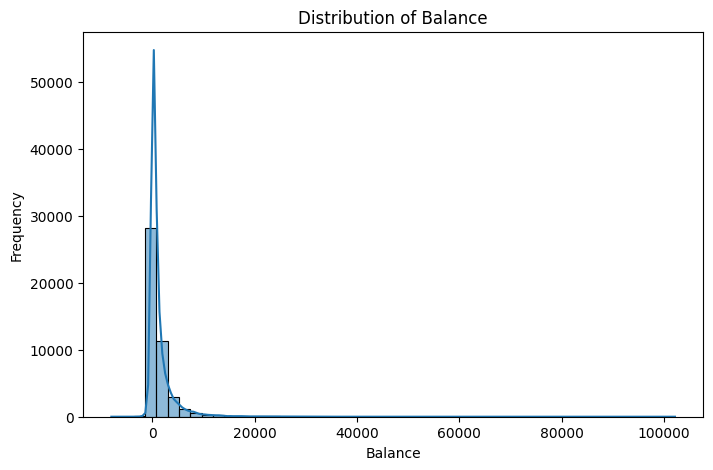

In [296]:
plt.figure(figsize=(8,5))
sns.histplot(df['balance'], bins=50, kde=True)

plt.title("Distribution of Balance")
plt.xlabel("Balance")
plt.ylabel("Frequency")

plt.show()

Berdasarkan hasil perhitungan skewness, variabel `balance` memiliki nilai skewness sebesar **8.36**. Nilai ini menunjukkan bahwa distribusi data sangat **right-skewed (miring ke kanan)**.

Hal ini berarti sebagian besar nasabah memiliki saldo rekening yang relatif kecil atau mendekati nol, sementara sebagian kecil nasabah memiliki saldo yang sangat besar. Pola seperti ini umum terjadi pada data finansial, di mana distribusi kekayaan atau saldo rekening biasanya tidak merata.

Visualisasi histogram juga memperkuat temuan tersebut. Grafik menunjukkan bahwa mayoritas data terkonsentrasi pada nilai saldo yang rendah, sedangkan terdapat ekor distribusi yang panjang ke arah kanan yang menunjukkan adanya beberapa nasabah dengan saldo yang sangat tinggi.

Selain itu, terdapat juga beberapa nilai saldo negatif yang kemungkinan menunjukkan kondisi **overdraft atau saldo minus**, yang masih masuk akal dalam konteks data perbankan.

Secara keseluruhan, meskipun distribusi `balance` sangat skewed, pola ini masih **wajar dan realistis untuk data finansial**, sehingga tidak menunjukkan adanya kesalahan atau anomali dalam data.

In [297]:
## keputusan untuk kolom balance

Hasil analisis menunjukkan bahwa variabel `balance` memiliki distribusi yang sangat **right-skewed**, yang terlihat dari nilai skewness yang tinggi serta bentuk histogram yang memiliki ekor panjang di sisi kanan. Hal ini menunjukkan bahwa sebagian besar nasabah memiliki saldo yang relatif kecil, sementara sebagian kecil nasabah memiliki saldo yang sangat besar.

Distribusi yang sangat skewed dapat mempengaruhi proses training pada model **Artificial Neural Network (ANN)**. Model ANN cukup sensitif terhadap distribusi dan skala data, sehingga fitur dengan distribusi yang sangat tidak seimbang dapat menyebabkan proses pembelajaran menjadi kurang stabil.

Salah satu teknik yang umum digunakan untuk mengurangi skewness adalah **log transformation**. Namun, pada variabel `balance` terdapat beberapa nilai **negatif**, sehingga transformasi log tidak dapat langsung diterapkan tanpa melakukan modifikasi tambahan pada data.

Oleh karena itu, untuk menjaga keaslian distribusi data sekaligus mengurangi pengaruh nilai ekstrem, kolom `balance` akan diproses menggunakan **RobustScaler** pada tahap preprocessing. RobustScaler dipilih karena metode ini menggunakan **median dan interquartile range (IQR)** sehingga lebih tahan terhadap pengaruh outlier dibandingkan metode scaling lainnya seperti StandardScaler atau MinMaxScaler.

Dengan menggunakan RobustScaler, diharapkan distribusi data menjadi lebih stabil dan proses training model ANN dapat berjalan dengan lebih optimal.

### c. day

In [298]:
day_counts = df['day'].value_counts().sort_index().reset_index()

day_counts.columns = ['day', 'count']

day_counts

,day,count
0,1,322
1,2,1293
2,3,1079
3,4,1445
4,5,1910
5,6,1932
6,7,1817
7,8,1842
8,9,1561
9,10,524


Berdasarkan hasil pemeriksaan awal terhadap dataset menggunakan fungsi seperti `df.info()`, `df.describe()`, serta pengecekan distribusi nilai pada beberapa kolom, dapat disimpulkan bahwa dataset berada dalam kondisi yang cukup baik.

Seluruh kolom memiliki jumlah **Non-Null values yang sama dengan total jumlah baris data**, yang menunjukkan bahwa **tidak terdapat missing value** pada dataset. Selain itu, tipe data pada setiap kolom juga sudah sesuai dengan karakteristik datanya, di mana variabel numerik disimpan dalam tipe `int64` dan variabel kategorikal disimpan dalam tipe `object`.

Tidak ditemukan pula masalah format data seperti nilai yang tidak konsisten, kesalahan penulisan kategori, ataupun format angka yang tidak valid. Hal ini menunjukkan bahwa dataset telah tersusun dengan baik dan siap digunakan untuk proses analisis lebih lanjut.

Dengan demikian, dataset dapat dianggap **bersih secara struktural**, sehingga tahap preprocessing selanjutnya dapat difokuskan pada transformasi data seperti encoding variabel kategorikal, scaling pada variabel numerik, serta persiapan data untuk proses pelatihan model.

In [299]:
invalid_dates = df[
    ((df['month'] == 'feb') & (df['day'] > 29)) |
    ((df['month'].isin(['apr','jun','sep','nov'])) & (df['day'] > 30))
]

invalid_dates

,age,job,marital,education,default,balance,housing,loan,contact,day,month,duration,campaign,pdays,previous,poutcome,y


Dilakukan pemeriksaan terhadap kombinasi variabel `month` dan `day` untuk memastikan tidak terdapat tanggal yang tidak valid, seperti bulan Februari dengan tanggal lebih dari 29 atau bulan yang hanya memiliki 30 hari (April, Juni, September, dan November) dengan tanggal lebih dari 30.

Hasil pemeriksaan menunjukkan bahwa **tidak ditemukan kombinasi bulan dan tanggal yang tidak valid** dalam dataset. Semua nilai pada kolom `day` masih berada dalam rentang yang sesuai dengan jumlah hari pada masing-masing bulan.

Hal ini menunjukkan bahwa variabel waktu pada dataset telah tercatat dengan **format yang konsisten dan valid**, sehingga tidak terdapat kesalahan pencatatan tanggal yang dapat mempengaruhi proses analisis atau pemodelan.

### d. duration

In [300]:
duration_counts = df['duration'].value_counts().sort_index(ascending=False).reset_index()

duration_counts.columns = ['duration', 'count']

duration_counts

,duration,count
0,4918,1
1,3881,1
2,3785,1
3,3422,1
4,3366,1
...,...,...
1568,4,15
1569,3,4
1570,2,3
1571,1,2


Berdasarkan hasil analisis value counts pada variabel `duration`, terlihat bahwa nilai durasi panggilan memiliki variasi yang cukup luas, mulai dari **0 detik hingga lebih dari 4000 detik**. Hal ini menunjukkan bahwa lama percakapan antara petugas pemasaran bank dan nasabah sangat bervariasi.

Sebagian besar nilai durasi berada pada rentang yang relatif rendah hingga menengah, sementara hanya sebagian kecil panggilan yang memiliki durasi sangat panjang. Kondisi ini masih **masuk akal dalam konteks kampanye pemasaran melalui telepon**, karena beberapa percakapan dapat berlangsung lama ketika nasabah tertarik atau membutuhkan penjelasan lebih lanjut mengenai produk yang ditawarkan.

Selain itu, terdapat beberapa data dengan nilai **duration = 0**. Nilai ini kemungkinan terjadi ketika panggilan telepon tidak berhasil tersambung atau nasabah tidak menjawab panggilan, sehingga tidak terjadi percakapan yang tercatat. Dalam konteks dataset telemarketing, kondisi ini masih dianggap **normal dan valid**, karena dataset mencatat setiap percobaan kontak yang dilakukan oleh bank.

Secara keseluruhan, nilai pada variabel `duration` masih **logis dan konsisten dengan proses telemarketing**, sehingga tidak menunjukkan adanya kesalahan format atau anomali data yang signifikan.

### e. campaign

In [301]:
campaign_counts = df['campaign'].value_counts().sort_index(ascending=False).reset_index()

campaign_counts.columns = ['campaign', 'count']

campaign_counts

,campaign,count
0,63,1
1,58,1
2,55,1
3,51,1
4,50,2
5,46,1
6,44,1
7,43,3
8,41,2
9,39,1


### f. pdays

Berdasarkan hasil analisis distribusi nilai pada variabel `campaign`, terlihat bahwa nilai yang muncul berada pada rentang yang logis dan masih sesuai dengan konteks kampanye pemasaran melalui telepon. Nilai `campaign` merepresentasikan jumlah kontak yang dilakukan kepada nasabah selama satu periode kampanye.

Sebagian besar nilai berada pada angka yang relatif kecil, yang menunjukkan bahwa nasabah umumnya dihubungi hanya beberapa kali dalam satu kampanye. Meskipun terdapat beberapa nilai yang lebih besar, kondisi ini masih dapat dianggap wajar karena dalam praktik telemarketing bank sering melakukan beberapa kali upaya kontak kepada nasabah yang belum memberikan respons.

Selain itu, tidak ditemukan nilai yang tidak masuk akal seperti nilai negatif atau format data yang tidak konsisten. Hal ini menunjukkan bahwa variabel `campaign` memiliki kualitas data yang baik dan tidak memerlukan proses pembersihan data tambahan sebelum digunakan dalam proses analisis maupun pemodelan.

In [302]:
pdays_counts = df['pdays'].value_counts().sort_index(ascending=False).reset_index()

pdays_counts.columns = ['pdays', 'count']

pdays_counts

,pdays,count
0,871,1
1,854,1
2,850,1
3,842,1
4,838,1
...,...,...
554,4,2
555,3,1
556,2,37
557,1,15


Variabel `pdays` menunjukkan jumlah hari sejak nasabah terakhir kali dihubungi pada kampanye pemasaran sebelumnya. Berdasarkan hasil analisis distribusi data, sebagian besar nilai pada kolom ini adalah **-1**. Nilai tersebut memiliki arti khusus dalam dataset, yaitu menandakan bahwa nasabah **belum pernah dihubungi pada kampanye sebelumnya**.

Distribusi nilai pada variabel `pdays` masih berada dalam rentang yang logis dan sesuai dengan konteks aktivitas telemarketing. Nilai selain -1 menunjukkan jumlah hari sejak kontak terakhir dilakukan, yang mencerminkan riwayat interaksi antara bank dan nasabah pada kampanye sebelumnya. Tidak ditemukan nilai yang tidak masuk akal atau kesalahan format pada kolom ini, sehingga data dapat dianggap **bersih dan valid untuk digunakan dalam analisis maupun pemodelan**.

Pada tahap analisis sempat dipertimbangkan untuk membuat fitur tambahan yang menunjukkan status apakah nasabah pernah dihubungi sebelumnya atau tidak. Namun karena nilai **-1 pada `pdays` sudah secara jelas merepresentasikan kondisi tersebut**, serta model **Artificial Neural Network (ANN)** mampu mempelajari pola dari nilai numerik secara langsung, maka fitur tambahan tersebut tidak dibuat dan variabel `pdays` tetap digunakan dalam bentuk aslinya.

### g. previous

In [303]:
poutcome_counts = df['previous'].value_counts().reset_index()

poutcome_counts.columns = ['previous', 'count']

poutcome_counts

,previous,count
0,0,36954
1,1,2772
2,2,2106
3,3,1142
4,4,714
5,5,459
6,6,277
7,7,205
8,8,129
9,9,92


Variabel `previous` menunjukkan jumlah kontak yang dilakukan kepada nasabah pada kampanye pemasaran sebelumnya. Berdasarkan hasil analisis distribusi nilai menggunakan value counts, sebagian besar nilai pada kolom ini adalah **0**, yang menunjukkan bahwa mayoritas nasabah dalam dataset **belum pernah dihubungi pada kampanye pemasaran sebelumnya**.

Hasil ini konsisten dengan distribusi pada variabel `pdays`, di mana terdapat **36.954 nilai `-1`** yang juga menunjukkan bahwa nasabah belum pernah dihubungi pada kampanye sebelumnya. Kesamaan jumlah tersebut menunjukkan bahwa kedua variabel ini **saling berhubungan dan merepresentasikan informasi yang konsisten mengenai riwayat kontak sebelumnya**.

Nilai selain 0 pada variabel `previous` menunjukkan jumlah kontak yang pernah dilakukan kepada nasabah pada kampanye sebelumnya, dengan jumlah yang relatif kecil dibandingkan dengan total dataset. Seluruh nilai pada kolom ini berada dalam rentang yang logis dan tidak ditemukan nilai negatif atau format data yang tidak konsisten.

Dengan demikian, variabel `previous` dapat dianggap **bersih, valid, dan tidak memerlukan proses pembersihan data tambahan**. Variabel ini nantinya hanya akan diproses melalui tahap **scaling(robust scaller) bersama variabel numerik lainnya** agar dapat digunakan secara optimal dalam model Artificial Neural Network (ANN).

## 2. Melakukan Pengecekan dan Perbaikan (jika ada), dan Persiapan untuk di pipeline nanti pada kolom Kategorik

In [304]:
## melihat kolom kolom di data 
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 45211 entries, 0 to 45210
Data columns (total 17 columns):
 #   Column     Non-Null Count  Dtype 
---  ------     --------------  ----- 
 0   age        45211 non-null  int64 
 1   job        45211 non-null  object
 2   marital    45211 non-null  object
 3   education  45211 non-null  object
 4   default    45211 non-null  object
 5   balance    45211 non-null  int64 
 6   housing    45211 non-null  object
 7   loan       45211 non-null  object
 8   contact    45211 non-null  object
 9   day        45211 non-null  int64 
 10  month      45211 non-null  object
 11  duration   45211 non-null  int64 
 12  campaign   45211 non-null  int64 
 13  pdays      45211 non-null  int64 
 14  previous   45211 non-null  int64 
 15  poutcome   45211 non-null  object
 16  y          45211 non-null  object
dtypes: int64(7), object(10)
memory usage: 5.9+ MB


### a. job

In [305]:
job_counts = df['job'].value_counts().reset_index()

job_counts.columns = ['job', 'count']

job_counts

,job,count
0,blue-collar,9732
1,management,9458
2,technician,7597
3,admin.,5171
4,services,4154
5,retired,2264
6,self-employed,1579
7,entrepreneur,1487
8,unemployed,1303
9,housemaid,1240


Variabel `job` menunjukkan jenis pekerjaan dari nasabah dalam dataset. Berdasarkan hasil value counts, terdapat beberapa kategori pekerjaan yang berbeda dengan distribusi yang cukup beragam. Kategori pekerjaan yang paling dominan adalah **blue-collar**, diikuti oleh **management** dan **technician**.

Distribusi ini menunjukkan bahwa nasabah bank dalam dataset berasal dari berbagai latar belakang pekerjaan, dengan proporsi yang cukup besar berasal dari sektor pekerjaan manual dan teknis. Selain itu, terdapat juga kategori **unknown**, yang menunjukkan bahwa informasi pekerjaan tidak tersedia atau tidak tercatat untuk sebagian kecil nasabah.

Secara keseluruhan, nilai pada variabel `job` masih konsisten dan tidak menunjukkan adanya kesalahan format atau kategori yang tidak masuk akal. Oleh karena itu, variabel ini dapat dianggap bersih dan siap digunakan pada tahap preprocessing, di mana nantinya akan dilakukan proses encoding agar dapat digunakan dalam model Artificial Neural Network (ANN).

### b. marital

In [306]:
marital_counts = df['marital'].value_counts().reset_index()

marital_counts.columns = ['marital', 'count']

marital_counts

,marital,count
0,married,27214
1,single,12790
2,divorced,5207


Variabel `marital` menunjukkan status pernikahan nasabah dalam dataset. Berdasarkan hasil distribusi data, terdapat tiga kategori utama yaitu **married**, **single**, dan **divorced**.

Kategori yang paling dominan adalah **married** dengan jumlah **27.214 data**, yang menunjukkan bahwa sebagian besar nasabah dalam dataset berstatus menikah. Selanjutnya diikuti oleh kategori **single** dengan **12.790 data**, dan **divorced** dengan **5.207 data**.

Distribusi ini menunjukkan bahwa mayoritas nasabah bank dalam dataset berada dalam kelompok individu yang sudah menikah, yang dapat mencerminkan kondisi demografis nasabah bank yang cenderung berada pada usia produktif dan memiliki stabilitas finansial yang lebih baik.

Selain itu, tidak ditemukan nilai yang tidak konsisten atau kategori yang tidak masuk akal pada variabel ini. Seluruh kategori juga memiliki jumlah data yang cukup untuk dianalisis. Oleh karena itu, variabel `marital` dapat dianggap **bersih dan valid** untuk digunakan dalam proses analisis maupun pemodelan. Pada tahap preprocessing, variabel ini nantinya akan diubah ke bentuk numerik melalui teknik encoding agar dapat digunakan dalam model Artificial Neural Network (ANN).

### c. education

In [307]:
education_counts = df['education'].value_counts().reset_index()

education_counts.columns = ['education', 'count']

education_counts

,education,count
0,secondary,23202
1,tertiary,13301
2,primary,6851
3,unknown,1857


Variabel `education` menunjukkan tingkat pendidikan dari nasabah dalam dataset. Berdasarkan hasil distribusi data, terdapat empat kategori utama yaitu **secondary**, **tertiary**, **primary**, dan **unknown**.

Kategori yang paling dominan adalah **secondary** dengan jumlah **23.202 data**, yang menunjukkan bahwa sebagian besar nasabah dalam dataset memiliki tingkat pendidikan menengah. Selanjutnya diikuti oleh kategori **tertiary** sebanyak **13.301 data**, yang merepresentasikan nasabah dengan pendidikan tinggi, serta **primary** sebanyak **6.851 data**, yang menunjukkan nasabah dengan tingkat pendidikan dasar.

Selain itu terdapat kategori **unknown** sebanyak **1.857 data**, yang menunjukkan bahwa informasi mengenai tingkat pendidikan tidak tersedia atau tidak tercatat untuk sebagian kecil nasabah. Jumlah kategori ini relatif kecil dibandingkan dengan kategori lainnya sehingga tidak memberikan dampak signifikan terhadap distribusi data secara keseluruhan.

Secara umum, distribusi pada variabel `education` terlihat wajar dan tidak menunjukkan adanya kesalahan format maupun nilai yang tidak masuk akal. Oleh karena itu, variabel ini dapat dianggap **bersih dan valid untuk digunakan dalam analisis maupun pemodelan**. Pada tahap preprocessing, variabel ini nantinya akan diubah menjadi bentuk numerik melalui proses encoding agar dapat digunakan dalam model Artificial Neural Network (ANN).

### d. default

In [308]:
default_counts = df['default'].value_counts().reset_index()

default_counts.columns = ['default', 'count']

default_counts

,default,count
0,no,44396
1,yes,815



Variabel `default` menunjukkan apakah nasabah memiliki riwayat kredit macet atau tidak. Berdasarkan hasil distribusi data, sebagian besar nasabah memiliki nilai **no**, yaitu sebanyak **44.396 data**, yang menunjukkan bahwa mayoritas nasabah dalam dataset tidak memiliki riwayat kredit macet.

Sementara itu, hanya terdapat **815 data** dengan nilai **yes**, yang menunjukkan bahwa hanya sebagian kecil nasabah yang memiliki riwayat kredit macet. Distribusi ini masih masuk akal dalam konteks perbankan, karena biasanya sebagian besar nasabah memiliki catatan kredit yang baik.

Secara keseluruhan, variabel `default` tidak menunjukkan adanya nilai yang tidak konsisten atau tidak masuk akal. Dengan demikian, data pada kolom ini dapat dianggap bersih dan valid untuk digunakan dalam analisis maupun pemodelan. Pada tahap preprocessing, variabel ini nantinya akan diubah menjadi bentuk numerik menggunakan teknik encoding agar dapat digunakan dalam model Artificial Neural Network (ANN).

### e. housing

In [309]:
housing_counts = df['housing'].value_counts().reset_index()

housing_counts.columns = ['housing', 'count']

housing_counts

,housing,count
0,yes,25130
1,no,20081


Variabel `housing` menunjukkan apakah nasabah memiliki pinjaman rumah atau tidak. Berdasarkan hasil distribusi data, terdapat dua kategori utama yaitu **yes** dan **no**.

Kategori **yes** memiliki jumlah sebanyak **25.130 data**, yang menunjukkan bahwa lebih dari setengah nasabah dalam dataset memiliki pinjaman rumah. Sementara itu, kategori **no** memiliki **20.081 data**, yang menunjukkan bahwa sebagian nasabah tidak memiliki pinjaman rumah.

Distribusi ini menunjukkan bahwa kepemilikan pinjaman rumah cukup umum di antara nasabah bank dalam dataset. Selain itu, tidak ditemukan nilai yang tidak konsisten atau tidak masuk akal pada variabel ini. Oleh karena itu, variabel `housing` dapat dianggap bersih dan valid untuk digunakan dalam analisis maupun pemodelan. Pada tahap preprocessing, variabel ini nantinya akan diubah menjadi bentuk numerik melalui teknik encoding agar dapat digunakan dalam model Artificial Neural Network (ANN).

### f. loan

In [310]:
loan_counts = df['loan'].value_counts().reset_index()

loan_counts.columns = ['loan', 'count']

loan_counts

,loan,count
0,no,37967
1,yes,7244


Variabel `loan` menunjukkan apakah nasabah memiliki pinjaman pribadi atau tidak. Berdasarkan hasil distribusi data, sebagian besar nasabah memiliki nilai **no**, yaitu sebanyak **37.967 data**, yang menunjukkan bahwa mayoritas nasabah dalam dataset tidak memiliki pinjaman pribadi.

Sementara itu, terdapat **7.244 data** dengan nilai **yes**, yang menunjukkan bahwa sebagian nasabah memiliki pinjaman pribadi. Distribusi ini masih masuk akal dalam konteks perbankan, karena tidak semua nasabah memiliki kewajiban pinjaman tambahan selain produk finansial lainnya.

Selain itu, tidak ditemukan nilai yang tidak konsisten atau format data yang tidak masuk akal pada variabel ini. Oleh karena itu, variabel `loan` dapat dianggap bersih dan valid untuk digunakan dalam proses analisis maupun pemodelan. Pada tahap preprocessing, variabel ini nantinya akan diubah ke bentuk numerik melalui teknik encoding agar dapat digunakan dalam model Artificial Neural Network (ANN).

### g. contact

In [311]:
contact_counts = df['contact'].value_counts().reset_index()

contact_counts.columns = ['contact', 'count']

contact_counts

,contact,count
0,cellular,29285
1,unknown,13020
2,telephone,2906


Variabel `contact` menunjukkan metode komunikasi yang digunakan oleh bank untuk menghubungi nasabah selama kampanye pemasaran. Berdasarkan hasil distribusi data, terdapat tiga kategori utama yaitu **cellular**, **telephone**, dan **unknown**.

Kategori **unknown** menunjukkan bahwa metode komunikasi yang digunakan untuk menghubungi nasabah tidak tercatat atau tidak diketahui pada data tersebut. Nilai ini bukan merupakan kesalahan data, melainkan hanya menunjukkan bahwa informasi mengenai metode kontak tidak tersedia.

Distribusi nilai pada variabel ini masih berada dalam kondisi yang wajar dan tidak ditemukan format data yang tidak konsisten maupun nilai yang tidak masuk akal. Oleh karena itu, variabel `contact` dapat dianggap **bersih dan aman untuk digunakan dalam analisis maupun pemodelan**.

Karena variabel ini bersifat kategorikal, pada tahap preprocessing variabel `con

### h. month

In [312]:
month_counts = df['month'].value_counts().reset_index()

month_counts.columns = ['month', 'count']

month_counts

,month,count
0,may,13766
1,jul,6895
2,aug,6247
3,jun,5341
4,nov,3970
5,apr,2932
6,feb,2649
7,jan,1403
8,oct,738
9,sep,579


Variabel `month` menunjukkan bulan ketika kontak pemasaran dilakukan kepada nasabah. Berdasarkan hasil distribusi data, kontak pemasaran dilakukan sepanjang tahun dengan variasi jumlah yang berbeda pada setiap bulan.

Bulan dengan jumlah kontak paling tinggi adalah **May** dengan **13.766 data**, yang menunjukkan bahwa sebagian besar aktivitas kampanye pemasaran dilakukan pada bulan tersebut. Sementara itu, bulan dengan jumlah kontak paling sedikit adalah **December** dengan **214 data**.

Perbedaan distribusi ini menunjukkan bahwa aktivitas telemarketing bank tidak dilakukan secara merata sepanjang tahun dan kemungkinan dipengaruhi oleh strategi pemasaran tertentu pada periode tertentu.

Selain itu, tidak ditemukan nilai yang tidak konsisten atau format data yang tidak masuk akal pada variabel ini. Oleh karena itu, variabel `month` dapat dianggap **bersih dan valid untuk digunakan dalam analisis maupun pemodelan**. Pada tahap preprocessing, variabel ini nantinya akan diubah menjadi bentuk numerik melalui teknik encoding agar dapat digunakan dalam model Artificial Neural Network (ANN).

### i. poutcome

In [313]:
poutcome_counts = df['poutcome'].value_counts().reset_index()

poutcome_counts.columns = ['poutcome', 'count']

poutcome_counts

,poutcome,count
0,unknown,36959
1,failure,4901
2,other,1840
3,success,1511


Variabel `poutcome` menunjukkan hasil dari kampanye pemasaran sebelumnya terhadap nasabah. Berdasarkan hasil distribusi data, kategori yang paling dominan adalah **unknown** dengan jumlah **36.954 data**, yang menunjukkan bahwa sebagian besar nasabah dalam dataset belum pernah dihubungi pada kampanye pemasaran sebelumnya.

Kategori lainnya seperti **failure**, **other**, dan **success** memiliki jumlah yang jauh lebih kecil. Hal ini menunjukkan bahwa hanya sebagian kecil nasabah yang memiliki riwayat interaksi pada kampanye pemasaran sebelumnya.

Kategori **unknown** bukan merupakan kesalahan data, melainkan menunjukkan bahwa informasi mengenai hasil kampanye sebelumnya tidak tersedia atau nasabah memang belum pernah dihubungi sebelumnya. Oleh karena itu, data pada kolom ini dapat dianggap **bersih dan valid** untuk digunakan dalam analisis maupun pemodelan.

Karena variabel `poutcome` bersifat kategorikal, maka pada tahap preprocessing variabel ini nantinya akan **diubah menjadi bentuk numerik melalui teknik encoding** agar dapat digunakan dalam model **Artificial Neural Network (ANN)**.

### j. y

In [314]:
y_counts = df['y'].value_counts().reset_index()

y_counts.columns = ['y', 'count']

y_counts

,y,count
0,no,39922
1,yes,5289


# C. Split Data

In [315]:
from sklearn.model_selection import train_test_split

X = df.drop('y', axis=1)
y = df['y']

X_train, X_temp, y_train, y_temp = train_test_split(
    X, y,
    test_size=0.30,
    random_state=42,
    stratify=y
)

In [316]:
X_val, X_test, y_val, y_test = train_test_split(
    X_temp, y_temp,
    test_size=0.5,
    random_state=42,
    stratify=y_temp
)

In [317]:
print(X_train.shape)
print(X_val.shape)
print(X_test.shape)

(31647, 16)
(6782, 16)
(6782, 16)


Dataset dibagi menjadi tiga bagian yaitu training, validation, dan test set. Data training digunakan untuk melatih model, validation set digunakan untuk memantau performa model selama proses training, sedangkan test set digunakan untuk mengevaluasi performa akhir model. Pembagian data dilakukan dengan proporsi 70% untuk training, 15% untuk validation, dan 15% untuk test.

# D. Jadikan Kolom Target Numerik

In [318]:
def encode_target(y):
    if y.dtype == 'object':
        return y.map({'no': 0, 'yes': 1}).astype('int32')
    return y.astype('int32')

y_train = encode_target(y_train)
y_val   = encode_target(y_val)
y_test  = encode_target(y_test)

print(y_train.value_counts())
print(y_val.value_counts())
print(y_test.value_counts())

y
0    27945
1     3702
Name: count, dtype: int64
y
0    5988
1     794
Name: count, dtype: int64
y
0    5989
1     793
Name: count, dtype: int64


# E. Pilih Kolom untuk Model

In [319]:
numeric_features = X_train.select_dtypes(include=['int64']).columns.tolist()
categorical_features = X_train.select_dtypes(include=['object']).columns.tolist()

print("Numeric features :", numeric_features)
print("Categorical features :", categorical_features)

Numeric features : ['age', 'balance', 'day', 'duration', 'campaign', 'pdays', 'previous']
Categorical features : ['job', 'marital', 'education', 'default', 'housing', 'loan', 'contact', 'month', 'poutcome']


# F. Prepocessing Pipeline

In [320]:
numeric_transformer = Pipeline(steps=[
    ('scaler', RobustScaler())
])

categorical_transformer = Pipeline(steps=[
    ('onehot', OneHotEncoder(handle_unknown='ignore', sparse_output=False))
])

preprocessor = ColumnTransformer(transformers=[
    ('num', numeric_transformer, numeric_features),
    ('cat', categorical_transformer, categorical_features)
])

Pada tahap preprocessing, dilakukan pembuatan pipeline terpisah untuk variabel numerik dan kategorikal agar setiap jenis data diproses dengan metode yang sesuai.

Untuk **fitur numerik**, digunakan **RobustScaler**. Pemilihan scaler ini didasarkan pada hasil analisis sebelumnya, di mana beberapa kolom numerik seperti `balance`, `duration`, dan `campaign` menunjukkan distribusi yang **skewed** serta memiliki **outlier**. RobustScaler dipilih karena proses scaling-nya menggunakan **median** dan **interquartile range (IQR)**, sehingga lebih tahan terhadap pengaruh nilai ekstrem dibandingkan StandardScaler atau MinMaxScaler. Dengan demikian, scaling ini lebih sesuai untuk data numerik pada dataset bank yang memiliki distribusi tidak merata dan beberapa nilai yang sangat tinggi atau rendah.

Untuk **fitur kategorikal**, digunakan **OneHotEncoder**. Hal ini dilakukan karena model Artificial Neural Network (ANN) tidak dapat langsung memproses data bertipe kategorikal atau string. OneHotEncoder mengubah setiap kategori menjadi representasi numerik dalam bentuk kolom biner. Selain itu, parameter `handle_unknown='ignore'` digunakan agar pipeline tetap aman ketika ditemukan kategori baru pada data validation atau test yang tidak muncul pada data training.


# G. Fit preprocessing hanya di train, lalu transform val dan test

In [321]:
X_train_processed = preprocessor.fit_transform(X_train)
X_val_processed   = preprocessor.transform(X_val)
X_test_processed  = preprocessor.transform(X_test)

X_train_processed = np.asarray(X_train_processed, dtype=np.float32)
X_val_processed   = np.asarray(X_val_processed, dtype=np.float32)
X_test_processed  = np.asarray(X_test_processed, dtype=np.float32)

y_train_np = np.asarray(y_train, dtype=np.float32)
y_val_np   = np.asarray(y_val, dtype=np.float32)
y_test_np  = np.asarray(y_test, dtype=np.float32)

print("X_train_processed shape:", X_train_processed.shape)
print("X_val_processed shape  :", X_val_processed.shape)
print("X_test_processed shape :", X_test_processed.shape)

X_train_processed shape: (31647, 51)
X_val_processed shape  : (6782, 51)
X_test_processed shape : (6782, 51)


Setelah preprocessing pipeline dibuat, langkah berikutnya adalah menerapkan pipeline tersebut pada data training, validation, dan test.

Pada **data training**, digunakan metode **`fit_transform()`**. Hal ini dilakukan karena pipeline perlu **mempelajari parameter transformasi** dari data training terlebih dahulu. Sebagai contoh, pada fitur numerik dengan `RobustScaler`, model perlu menghitung **median** dan **interquartile range (IQR)** dari data training. Begitu juga pada fitur kategorikal dengan `OneHotEncoder`, pipeline perlu mempelajari kategori-kategori apa saja yang muncul pada data training.

Sementara itu, pada **data validation** dan **data test** hanya digunakan metode **`transform()`**. Hal ini karena kedua dataset tersebut tidak boleh digunakan untuk mempelajari parameter preprocessing. Data validation dan test hanya boleh diproses menggunakan parameter yang **sudah dipelajari dari data training** agar evaluasi model tetap adil dan realistis.

Pendekatan ini sangat penting untuk mencegah **data leakage**, yaitu kondisi ketika informasi dari validation atau test secara tidak sengaja ikut digunakan dalam proses pelatihan model. Jika hal tersebut terjadi, performa model bisa terlihat lebih baik dari yang sebenarnya karena model telah “melihat” sebagian informasi dari data evaluasi.

Selain itu, setelah proses transformasi selesai, hasil preprocessing diubah menjadi tipe **`float32`** agar sesuai dengan format numerik yang lebih sesuai digunakan dalam pelatihan model Artificial Neural Network (ANN).

# H. Hitung Class Weight (karena dataset tidak seimbang)

In [322]:
classes = np.unique(y_train_np)

class_weights = compute_class_weight(
    class_weight='balanced',
    classes=classes,
    y=y_train_np
)

class_weight_dict = {int(cls): float(weight) for cls, weight in zip(classes, class_weights)}
print("Class weights:", class_weight_dict)

Class weights: {0: 0.5662372517444981, 1: 4.274311183144246}


Pada dataset ini terdapat ketidakseimbangan jumlah kelas pada target variabel `y`. Sebagian besar data berada pada kelas **0 (tidak melakukan deposit)**, sedangkan jumlah data pada kelas **1 (melakukan deposit)** jauh lebih sedikit. Ketidakseimbangan ini dapat menyebabkan model cenderung memprediksi kelas mayoritas dan mengabaikan kelas minoritas.

Untuk mengatasi masalah tersebut, dilakukan perhitungan **class weight** menggunakan fungsi `compute_class_weight` dari library scikit-learn dengan parameter `class_weight='balanced'`. Metode ini secara otomatis memberikan bobot yang lebih besar pada kelas yang jumlahnya lebih sedikit dan bobot yang lebih kecil pada kelas yang jumlahnya lebih banyak.

Pada kode di atas, pertama-tama diambil seluruh nilai kelas unik dari `y_train_np`. Kemudian fungsi `compute_class_weight` digunakan untuk menghitung bobot masing-masing kelas berdasarkan distribusi data pada training set. Hasilnya kemudian dikonversi menjadi dictionary agar dapat digunakan langsung pada proses training model.

Hasil perhitungan menunjukkan bahwa:

- **Class 0 memiliki weight sebesar 0.566**
- **Class 1 memiliki weight sebesar 4.274**

Nilai ini menunjukkan bahwa kesalahan prediksi pada **kelas 1 akan diberi penalti sekitar 4.27 kali lebih besar** dibandingkan kelas 0. Dengan demikian, model akan lebih memperhatikan pola pada kelas minoritas sehingga diharapkan mampu meningkatkan kemampuan model dalam mendeteksi pelanggan yang benar-benar melakukan deposit.

# I. Callback untuk training (PERTANYAAN BONUS)


In [323]:
#  Saya pakai: EarlyStopping, ModelCheckpoint, CSVLogger, ReduceLROnPlateau

os.makedirs("models", exist_ok=True)
os.makedirs("logs", exist_ok=True)

callbacks_seq = [
    EarlyStopping(
        monitor='val_loss',
        patience=10,
        restore_best_weights=True,
        verbose=1
    ),
    ModelCheckpoint(
        filepath='models/best_sequential_model.keras',
        monitor='val_loss',
        save_best_only=True,
        verbose=1
    ),
    CSVLogger(
        filename='logs/sequential_training_log.csv',
        append=False
    ),
    ReduceLROnPlateau(
        monitor='val_loss',
        factor=0.5,
        patience=5,
        min_lr=1e-6,
        verbose=1
    )
]

callbacks_func = [
    EarlyStopping(
        monitor='val_loss',
        patience=10,
        restore_best_weights=True,
        verbose=1
    ),
    ModelCheckpoint(
        filepath='models/best_functional_model.keras',
        monitor='val_loss',
        save_best_only=True,
        verbose=1
    ),
    CSVLogger(
        filename='logs/functional_training_log.csv',
        append=False
    ),
    ReduceLROnPlateau(
        monitor='val_loss',
        factor=0.5,
        patience=5,
        min_lr=1e-6,
        verbose=1
    )
]

Pada proses training model Artificial Neural Network (ANN), digunakan beberapa **callback** untuk meningkatkan stabilitas dan efisiensi proses pelatihan. Callback memungkinkan model memonitor performa selama training dan secara otomatis mengambil tindakan tertentu ketika kondisi tertentu terjadi.

Beberapa callback yang digunakan pada model ini antara lain **EarlyStopping, ModelCheckpoint, CSVLogger, dan ReduceLROnPlateau**.

**EarlyStopping** digunakan untuk menghentikan proses training secara otomatis apabila nilai **validation loss** tidak mengalami perbaikan selama sejumlah epoch tertentu (patience = 10). Hal ini membantu mencegah terjadinya **overfitting** serta menghindari proses training yang terlalu lama ketika model sudah tidak lagi mengalami peningkatan performa. Selain itu, parameter `restore_best_weights=True` memastikan bahwa bobot model yang digunakan adalah bobot terbaik yang diperoleh selama proses training.

**ModelCheckpoint** digunakan untuk menyimpan model terbaik selama proses training. Model akan disimpan setiap kali nilai **validation loss** mengalami perbaikan, sehingga model terbaik tetap tersedia meskipun performa model pada epoch berikutnya menurun.

**CSVLogger** digunakan untuk mencatat seluruh proses training ke dalam file log dalam format CSV. File ini menyimpan informasi seperti nilai loss, validation loss, dan metrik lainnya pada setiap epoch. Catatan ini berguna untuk melakukan analisis performa model serta memvisualisasikan proses pembelajaran model.

**ReduceLROnPlateau** digunakan untuk menyesuaikan **learning rate** secara otomatis ketika model mengalami stagnasi. Jika validation loss tidak mengalami perbaikan selama beberapa epoch (patience = 5), maka learning rate akan dikurangi dengan faktor tertentu (factor = 0.5). Penurunan learning rate ini membantu model untuk melakukan pencarian parameter yang lebih optimal dan meningkatkan peluang mencapai konvergensi yang lebih baik.

Dengan penggunaan callback tersebut, proses training menjadi lebih **efisien, stabil, dan terkontrol**, sehingga model dapat mencapai performa yang lebih optimal tanpa risiko overfitting yang berlebihan.

# J. Build ANN Sequential model

In [324]:
# Saya tambahkan: BatchNormalization, Dropout, L2 regularization
input_dim = X_train_processed.shape[1]

sequential_model = Sequential([
    Input(shape=(input_dim,)),
    
    Dense(128, activation='relu', kernel_regularizer=l2(1e-4)),
    BatchNormalization(),
    Dropout(0.30),
    
    Dense(64, activation='relu', kernel_regularizer=l2(1e-4)),
    BatchNormalization(),
    Dropout(0.25),
    
    Dense(32, activation='relu', kernel_regularizer=l2(1e-4)),
    BatchNormalization(),
    Dropout(0.20),
    
    Dense(1, activation='sigmoid')
])

sequential_model.compile(
    optimizer=Adam(learning_rate=1e-3),
    loss='binary_crossentropy',
    metrics=[
        'accuracy',
        tf.keras.metrics.AUC(name='auc'),
        tf.keras.metrics.Precision(name='precision'),
        tf.keras.metrics.Recall(name='recall')
    ]
)

sequential_model.summary()

Model: "sequential_3"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense_20 (Dense)                │ (None, 128)            │         6,656 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_15          │ (None, 128)            │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_15 (Dropout)            │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_21 (Dense)                │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_16          │ (None, 64)             │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_16 (Dropout)            │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_22 (Dense)                │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_17          │ (None, 32)             │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_17 (Dropout)            │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_23 (Dense)                │ (None, 1)              │            33 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 17,921 (70.00 KB)

 Trainable params: 17,473 (68.25 KB)

 Non-trainable params: 448 (1.75 KB)

Pada tahap ini dibangun model **Artificial Neural Network (ANN)** menggunakan arsitektur **Sequential**. Model menerima input berupa fitur hasil preprocessing dengan jumlah dimensi sebesar `input_dim`.

Arsitektur jaringan terdiri dari **tiga hidden layer** dengan jumlah neuron yang menurun yaitu **128, 64, dan 32**. Struktur ini bertujuan untuk mengekstraksi pola dari data secara bertahap hingga menghasilkan representasi fitur yang lebih ringkas sebelum menghasilkan prediksi akhir.

Setiap hidden layer menggunakan **aktivasi ReLU** karena mampu mempercepat proses training dan membantu mengurangi masalah vanishing gradient. Untuk meningkatkan stabilitas model dan mencegah overfitting, diterapkan beberapa teknik regularisasi yaitu:

- **L2 Regularization** untuk membatasi bobot yang terlalu besar.
- **BatchNormalization** untuk menstabilkan distribusi output antar layer.
- **Dropout** untuk menonaktifkan sebagian neuron secara acak selama training (30%, 25%, dan 20%).

Pada **output layer** digunakan **1 neuron dengan aktivasi sigmoid** karena permasalahan yang diselesaikan merupakan **binary classification**.

Model kemudian dikompilasi menggunakan **optimizer Adam** dengan learning rate `0.001` serta **loss binary crossentropy**, yang sesuai untuk klasifikasi dua kelas. Untuk memantau performa model selama training digunakan beberapa metrik yaitu **accuracy, AUC, precision, dan recall**.

# K. Train ANN Sequential model

In [343]:
history_seq = sequential_model.fit(
    X_train_processed, y_train_np,
    validation_data=(X_val_processed, y_val_np),
    epochs=100,
    batch_size=32,
    class_weight=class_weight_dict,
    callbacks=callbacks_seq,
    verbose=1
)

Epoch 1/100
970/989 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - accuracy: 0.8355 - auc: 0.9271 - loss: 0.3437 - precision: 0.4094 - recall: 0.9014
Epoch 1: val_loss did not improve from 0.32199
989/989 ━━━━━━━━━━━━━━━━━━━━ 1s 1ms/step - accuracy: 0.8340 - auc: 0.9282 - loss: 0.3402 - precision: 0.4062 - recall: 0.9079 - val_accuracy: 0.8462 - val_auc: 0.9306 - val_loss: 0.3425 - val_precision: 0.4247 - val_recall: 0.8841 - learning_rate: 6.2500e-05
Epoch 2/100
977/989 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - accuracy: 0.8331 - auc: 0.9269 - loss: 0.3415 - precision: 0.4034 - recall: 0.9142
Epoch 2: val_loss did not improve from 0.32199
989/989 ━━━━━━━━━━━━━━━━━━━━ 1s 1ms/step - accuracy: 0.8345 - auc: 0.9295 - loss: 0.3372 - precision: 0.4076 - recall: 0.9155 - val_accuracy: 0.8472 - val_auc: 0.9309 - val_loss: 0.3442 - val_precision: 0.4266 - val_recall: 0.8854 - learning_rate: 6.2500e-05
Epoch 3/100
979/989 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - accuracy: 0.8315 - auc: 0.9308 - loss: 0.3359 - precision

Model ANN dilatih menggunakan data training dengan **batch size 32** dan maksimum **100 epoch**. Selain itu, digunakan **class weight** untuk mengatasi ketidakseimbangan dataset sehingga model dapat lebih memperhatikan kelas minoritas.

Selama proses training, performa model dimonitor menggunakan **validation data**. Beberapa callback juga digunakan untuk meningkatkan stabilitas training, seperti **EarlyStopping** untuk menghentikan training ketika model tidak lagi mengalami perbaikan, serta **ReduceLROnPlateau** untuk menurunkan learning rate ketika validation loss stagnan.

Berdasarkan hasil training, model berhenti pada **epoch ke-33** karena EarlyStopping aktif dan bobot terbaik dipulihkan dari **epoch ke-23**. Hal ini menunjukkan bahwa model telah mencapai performa optimal sebelum mencapai batas maksimum epoch yang ditentukan.

# L. Build ANN Functional model

In [326]:
inputs = Input(shape=(input_dim,))

x = Dense(128, activation='relu', kernel_regularizer=l2(1e-4))(inputs)
x = BatchNormalization()(x)
x = Dropout(0.30)(x)

x = Dense(64, activation='relu', kernel_regularizer=l2(1e-4))(x)
x = BatchNormalization()(x)
x = Dropout(0.25)(x)

x = Dense(32, activation='relu', kernel_regularizer=l2(1e-4))(x)
x = BatchNormalization()(x)
x = Dropout(0.20)(x)

outputs = Dense(1, activation='sigmoid')(x)

functional_model = Model(inputs=inputs, outputs=outputs)

functional_model.compile(
    optimizer=Adam(learning_rate=1e-3),
    loss='binary_crossentropy',
    metrics=[
        'accuracy',
        tf.keras.metrics.AUC(name='auc'),
        tf.keras.metrics.Precision(name='precision'),
        tf.keras.metrics.Recall(name='recall')
    ]
)

functional_model.summary()

Model: "functional_6"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_6 (InputLayer)      │ (None, 51)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_24 (Dense)                │ (None, 128)            │         6,656 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_18          │ (None, 128)            │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_18 (Dropout)            │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_25 (Dense)                │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_19          │ (None, 64)             │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_19 (Dropout)            │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_26 (Dense)                │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_20          │ (None, 32)             │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_20 (Dropout)            │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_27 (Dense)                │ (None, 1)              │            33 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 17,921 (70.00 KB)

 Trainable params: 17,473 (68.25 KB)

 Non-trainable params: 448 (1.75 KB)

Model Artificial Neural Network (ANN) dibangun menggunakan **Functional API** dari Keras. Pendekatan ini memberikan fleksibilitas lebih dalam mendefinisikan hubungan antara input dan output layer dibandingkan model Sequential.

Model menerima input berupa fitur hasil preprocessing dengan dimensi `input_dim`. Arsitektur jaringan terdiri dari **tiga hidden layer** dengan jumlah neuron yang menurun yaitu **128 → 64 → 32**. Struktur ini bertujuan untuk mengekstraksi pola dari data secara bertahap hingga menghasilkan representasi fitur yang lebih ringkas sebelum menghasilkan prediksi akhir.

Setiap hidden layer menggunakan **aktivasi ReLU**, yang umum digunakan pada deep learning karena mampu mempercepat proses training dan mengurangi masalah vanishing gradient. Selain itu, diterapkan beberapa teknik regularisasi untuk meningkatkan stabilitas model dan mencegah overfitting, yaitu:

- **L2 Regularization** untuk membatasi bobot yang terlalu besar.
- **BatchNormalization** untuk menstabilkan distribusi output antar layer sehingga training lebih stabil.
- **Dropout** untuk menonaktifkan sebagian neuron secara acak selama training (30%, 25%, dan 20%) agar model tidak terlalu bergantung pada neuron tertentu.

Pada **output layer**, digunakan **1 neuron dengan aktivasi sigmoid** karena masalah yang diselesaikan merupakan **binary classification**. Aktivasi sigmoid menghasilkan probabilitas antara 0 dan 1 yang menunjukkan kemungkinan suatu data termasuk ke kelas positif.

Model kemudian dikompilasi menggunakan **optimizer Adam** dengan learning rate `0.001` serta **loss binary crossentropy**, yang sesuai untuk klasifikasi dua kelas. Untuk memantau performa model selama training, digunakan beberapa metrik evaluasi yaitu **accuracy, AUC, precision, dan recall**, sehingga performa model dapat dianalisis secara lebih komprehensif.

# M. Train ANN Functional model

In [327]:
history_func = functional_model.fit(
    X_train_processed, y_train_np,
    validation_data=(X_val_processed, y_val_np),
    epochs=100,
    batch_size=32,
    class_weight=class_weight_dict,
    callbacks=callbacks_func,
    verbose=1
)

Epoch 1/100
959/989 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - accuracy: 0.6582 - auc: 0.7599 - loss: 0.6281 - precision: 0.2238 - recall: 0.7551
Epoch 1: val_loss improved from None to 0.43396, saving model to models/best_functional_model.keras
989/989 ━━━━━━━━━━━━━━━━━━━━ 3s 2ms/step - accuracy: 0.7089 - auc: 0.8164 - loss: 0.5527 - precision: 0.2585 - recall: 0.7963 - val_accuracy: 0.8009 - val_auc: 0.8812 - val_loss: 0.4340 - val_precision: 0.3462 - val_recall: 0.7884 - learning_rate: 0.0010
Epoch 2/100
971/989 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - accuracy: 0.7587 - auc: 0.8786 - loss: 0.4526 - precision: 0.3110 - recall: 0.8474
Epoch 2: val_loss improved from 0.43396 to 0.40957, saving model to models/best_functional_model.keras
989/989 ━━━━━━━━━━━━━━━━━━━━ 1s 1ms/step - accuracy: 0.7644 - auc: 0.8771 - loss: 0.4533 - precision: 0.3126 - recall: 0.8458 - val_accuracy: 0.8039 - val_auc: 0.9132 - val_loss: 0.4096 - val_precision: 0.3637 - val_recall: 0.9005 - learning_rate: 0.0010
Epoch 3/100

Model ANN dengan arsitektur Functional dilatih menggunakan **batch size 32**, **maksimum 100 epoch**, serta **class weight** untuk mengatasi ketidakseimbangan dataset. Selama proses training, performa model dimonitor menggunakan **validation data** serta beberapa callback seperti **EarlyStopping** dan **ReduceLROnPlateau**.

Berdasarkan hasil training, performa model menunjukkan peningkatan yang cukup stabil pada beberapa epoch awal, ditandai dengan penurunan **validation loss** dan peningkatan **AUC**. Pada epoch ke-40, callback **ReduceLROnPlateau** menurunkan learning rate untuk membantu proses optimisasi ketika model mulai stagnan.

Training akhirnya dihentikan secara otomatis oleh **EarlyStopping**, dan bobot model terbaik dipulihkan dari **epoch ke-30**. Pada hasil terbaik, model mencapai **validation accuracy sekitar 0.85** dan **AUC sekitar 0.93**, yang menunjukkan kemampuan model yang cukup baik dalam membedakan antara pelanggan yang melakukan deposit dan yang tidak.

# N. Function untuk plot history

In [328]:
def plot_training_history(history, title_prefix="Model"):
    history_df = pd.DataFrame(history.history)
    
    plt.figure(figsize=(8, 5))
    plt.plot(history_df['loss'], label='train_loss')
    plt.plot(history_df['val_loss'], label='val_loss')
    plt.title(f'{title_prefix} - Loss')
    plt.xlabel('Epoch')
    plt.ylabel('Loss')
    plt.legend()
    plt.show()

    plt.figure(figsize=(8, 5))
    plt.plot(history_df['accuracy'], label='train_accuracy')
    plt.plot(history_df['val_accuracy'], label='val_accuracy')
    plt.title(f'{title_prefix} - Accuracy')
    plt.xlabel('Epoch')
    plt.ylabel('Accuracy')
    plt.legend()
    plt.show()

Plot ini saya gunakan untuk membandingkan antara validation loss dengan train loss dan validation accuracy dengan train accuracy

# O. Plot history Sequential

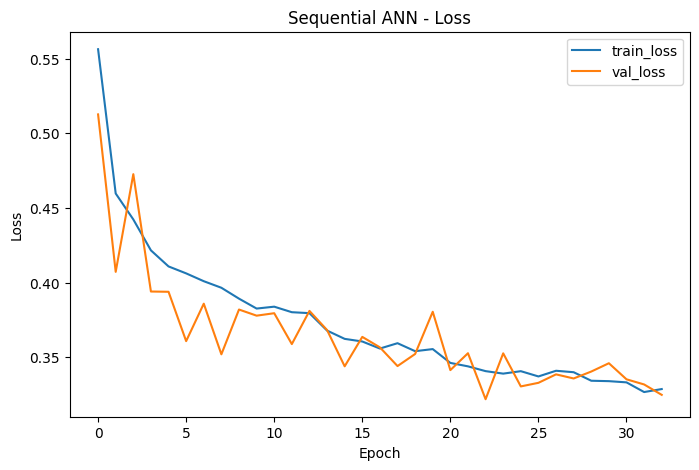

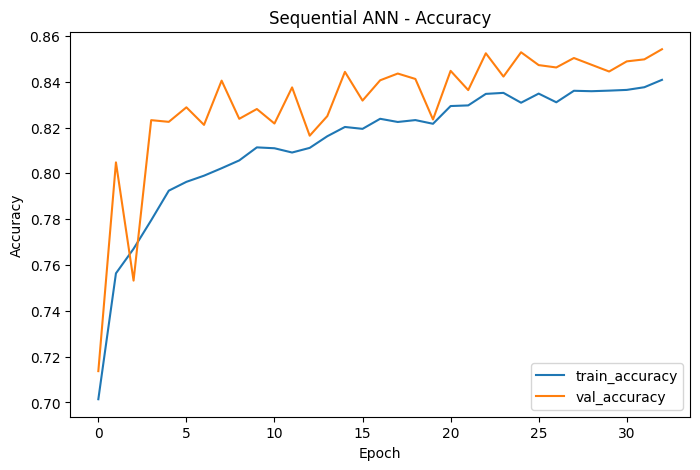

In [329]:
plot_training_history(history_seq, title_prefix="Sequential ANN")

### Analisis Training History Sequential ANN

Berdasarkan grafik loss, terlihat bahwa **training loss dan validation loss sama-sama menurun seiring bertambahnya epoch**, yang menunjukkan bahwa model berhasil mempelajari pola dari data dengan baik. Kedua kurva juga berada cukup dekat satu sama lain, sehingga tidak terlihat adanya overfitting yang signifikan.

Pada grafik accuracy, **training accuracy meningkat secara bertahap hingga sekitar 0.84**, sementara **validation accuracy mencapai sekitar 0.85**. Nilai validation accuracy yang sedikit lebih tinggi menunjukkan bahwa model mampu melakukan generalisasi dengan baik pada data yang tidak digunakan selama proses training.

Secara keseluruhan, model Sequential ANN menunjukkan **proses pembelajaran yang stabil, performa yang konsisten antara data training dan validation, serta kemampuan generalisasi yang cukup baik.**

# P. Plot history Functional

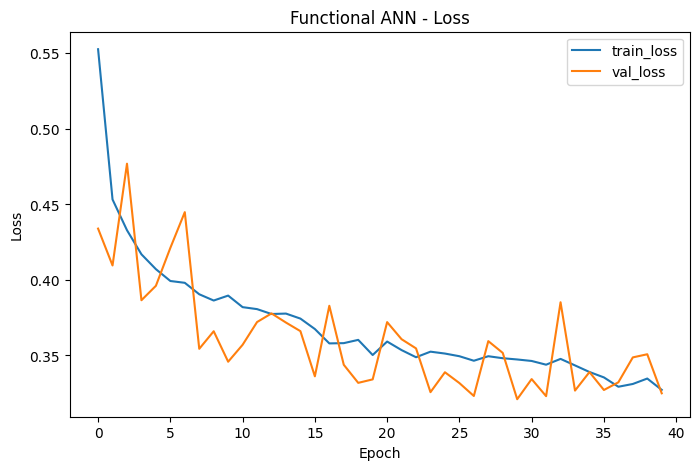

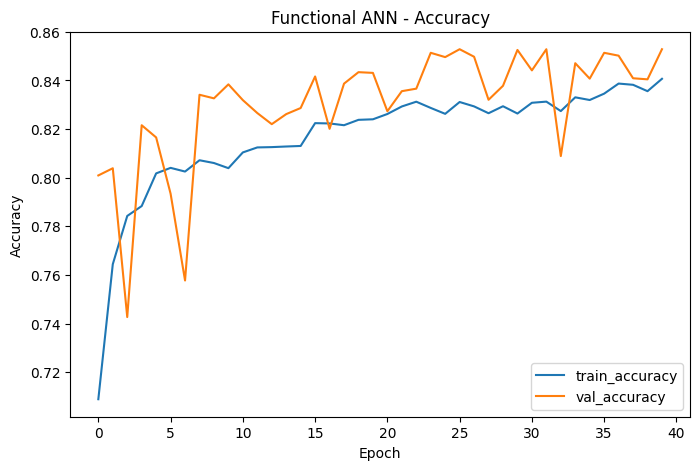

In [330]:
plot_training_history(history_func, title_prefix="Functional ANN")

### Analisis Training History Functional ANN

Berdasarkan grafik training history, terlihat bahwa **training loss dan validation loss sama-sama mengalami penurunan seiring bertambahnya epoch**, yang menunjukkan bahwa model berhasil mempelajari pola dari data dengan baik. Nilai validation loss juga mengikuti tren yang mirip dengan training loss, sehingga tidak terlihat indikasi overfitting yang signifikan.

Pada grafik accuracy, **training accuracy meningkat secara bertahap hingga sekitar 0.84**, sementara **validation accuracy mencapai sekitar 0.85**. Kedua kurva juga berada pada rentang yang cukup dekat, yang menunjukkan bahwa model memiliki kemampuan generalisasi yang baik terhadap data yang tidak digunakan dalam training.

Secara keseluruhan, grafik ini menunjukkan bahwa proses training berjalan cukup stabil, model mampu belajar secara efektif dari data, dan performa pada data validation tetap konsisten tanpa perbedaan yang terlalu besar dengan data training.

# Q. Function evaluasi model

In [ ]:
def evaluate_model(model, X_test, y_test, model_name="Model"):
    # evaluate loss & metrics from keras
    test_results = model.evaluate(X_test, y_test, verbose=0)
    metric_names = model.metrics_names
    
    print(f"\n===== {model_name} - Test Evaluation =====")
    for name, value in zip(metric_names, test_results):
        print(f"{name}: {value:.4f}")
    
    # prediction
    y_prob = model.predict(X_test, verbose=0).ravel()
    y_pred = (y_prob >= 0.5).astype(int)

    acc = accuracy_score(y_test, y_pred)
    prec = precision_score(y_test, y_pred, zero_division=0)
    rec = recall_score(y_test, y_pred, zero_division=0)
    f1 = f1_score(y_test, y_pred, zero_division=0)
    auc = roc_auc_score(y_test, y_prob)


    print(f"Accuracy : {acc:.4f}")
    print(f"Precision: {prec:.4f}")
    print(f"Recall   : {rec:.4f}")
    print(f"F1-Score : {f1:.4f}")
    print(f"ROC-AUC  : {auc:.4f}")

    print("\nClassification Report")
    print(classification_report(y_test, y_pred, digits=4))

    cm = confusion_matrix(y_test, y_pred)
    plt.figure(figsize=(5, 4))
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues')
    plt.title(f'{model_name} - Confusion Matrix')
    plt.xlabel('Predicted')
    plt.ylabel('Actual')
    plt.show()

    return {
        'model_name': model_name,
        'loss': float(test_results[0]),
        'accuracy': float(acc),
        'precision': float(prec),
        'recall': float(rec),
        'f1_score': float(f1),
        'roc_auc': float(auc)
    }

# R. Evaluate Sequential model


===== Sequential ANN - Test Evaluation =====
loss: 0.3482
compile_metrics: 0.8408

Additional Metrics
Accuracy : 0.8408
Precision: 0.4110
Recall   : 0.8361
F1-Score : 0.5511
ROC-AUC  : 0.9151

Classification Report
              precision    recall  f1-score   support

         0.0     0.9749    0.8414    0.9032      5989
         1.0     0.4110    0.8361    0.5511       793

    accuracy                         0.8408      6782
   macro avg     0.6929    0.8387    0.7272      6782
weighted avg     0.9089    0.8408    0.8620      6782



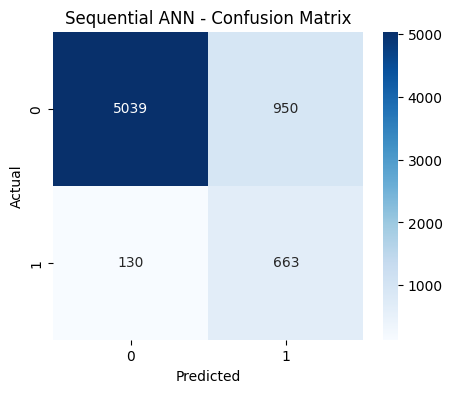

In [332]:
seq_results = evaluate_model(
    sequential_model,
    X_test_processed,
    y_test_np,
    model_name="Sequential ANN"
)

### Evaluasi Model Sequential ANN

Berdasarkan hasil evaluasi pada data test, model Sequential ANN memperoleh accuracy sebesar 0.8408 dan ROC-AUC sebesar 0.9151. Nilai ROC-AUC yang tinggi menunjukkan bahwa model memiliki kemampuan yang cukup baik dalam membedakan antara kelas positif dan negatif.

Namun, jika dilihat lebih dalam pada metrik precision dan recall, terlihat adanya ketidakseimbangan performa. Model memiliki recall yang cukup tinggi pada kelas positif yaitu sebesar 0.8361, yang berarti sebagian besar kasus positif berhasil terdeteksi oleh model. Akan tetapi precision hanya sebesar 0.4110, yang menunjukkan bahwa cukup banyak prediksi positif yang ternyata bukan benar-benar positif.

Hal ini juga terlihat pada confusion matrix. Dari total data test, terdapat:
- 5039 data yang benar diprediksi sebagai kelas 0 (True Negative)
- 663 data yang benar diprediksi sebagai kelas 1 (True Positive)
- 950 data yang sebenarnya kelas 0 tetapi diprediksi sebagai kelas 1 (False Positive)
- 130 data yang sebenarnya kelas 1 tetapi diprediksi sebagai kelas 0 (False Negative)

Artinya model cenderung **lebih agresif dalam memprediksi kelas positif**, sehingga mampu menangkap banyak kasus positif, tetapi juga menghasilkan cukup banyak false alarm.

Sebagai ilustrasi dalam konteks bisnis, misalnya terdapat **10.000 pelanggan**, dan sekitar **5.000 pelanggan benar-benar merupakan target positif** (misalnya pelanggan yang akan melakukan repeat purchase). Dengan pola performa model saat ini, model kemungkinan dapat **menangkap sebagian besar pelanggan yang benar-benar akan repeat**, tetapi juga akan **mengidentifikasi sejumlah pelanggan lain sebagai target padahal sebenarnya tidak**.

Dalam praktik bisnis, kondisi ini memiliki dua sisi. Di satu sisi, perusahaan memiliki peluang lebih besar untuk tidak melewatkan pelanggan potensial (high recall). Namun di sisi lain, biaya pemasaran atau promosi bisa menjadi lebih besar karena sebagian pelanggan yang ditargetkan sebenarnya tidak termasuk pelanggan yang benar-benar akan melakukan repeat.

Secara keseluruhan, model sudah menunjukkan kemampuan klasifikasi yang cukup baik, tetapi masih terdapat ruang untuk peningkatan terutama pada **precision**, agar prediksi positif yang dihasilkan menjadi lebih akurat dan lebih efisien untuk pengambilan keputusan bisnis.

# S. Evaluate Functional model


===== Sequential ANN - Test Evaluation =====
loss: 0.3482
compile_metrics: 0.8408

Additional Metrics
Accuracy : 0.8408
Precision: 0.4110
Recall   : 0.8361
F1-Score : 0.5511
ROC-AUC  : 0.9151

Classification Report
              precision    recall  f1-score   support

         0.0     0.9749    0.8414    0.9032      5989
         1.0     0.4110    0.8361    0.5511       793

    accuracy                         0.8408      6782
   macro avg     0.6929    0.8387    0.7272      6782
weighted avg     0.9089    0.8408    0.8620      6782



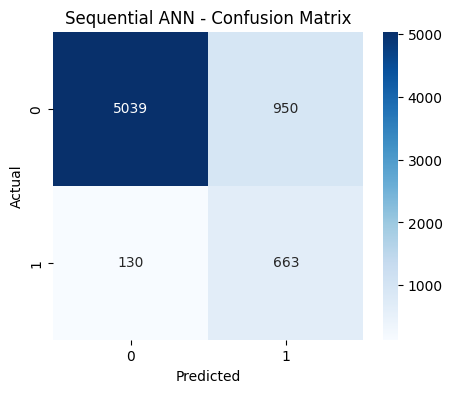

In [333]:
seq_results = evaluate_model(
    sequential_model,
    X_test_processed,
    y_test_np,
    model_name="Sequential ANN"
)


===== Functional ANN - Test Evaluation =====
loss: 0.3447
compile_metrics: 0.8381

Additional Metrics
Accuracy : 0.8381
Precision: 0.4082
Recall   : 0.8550
F1-Score : 0.5526
ROC-AUC  : 0.9189

Classification Report
              precision    recall  f1-score   support

         0.0     0.9775    0.8359    0.9012      5989
         1.0     0.4082    0.8550    0.5526       793

    accuracy                         0.8381      6782
   macro avg     0.6929    0.8454    0.7269      6782
weighted avg     0.9110    0.8381    0.8604      6782



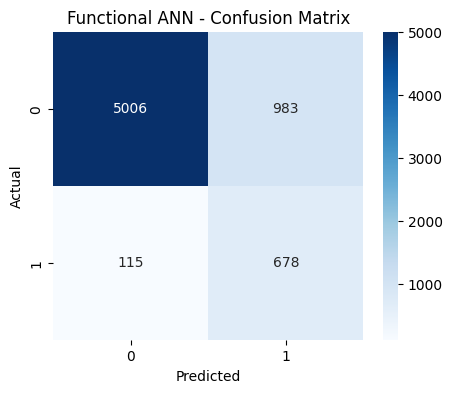

In [334]:
func_results = evaluate_model(
    functional_model,
    X_test_processed,
    y_test_np,
    model_name="Functional ANN"
)

### Evaluasi Model Functional ANN

Berdasarkan hasil evaluasi pada data test, model Functional ANN memperoleh accuracy sebesar 0.8381 dan ROC-AUC sebesar 0.9189. Nilai ROC-AUC yang tinggi menunjukkan bahwa model memiliki kemampuan yang baik dalam membedakan antara kelas positif dan negatif.

Jika dilihat dari metrik lainnya, model memiliki recall yang cukup tinggi pada kelas positif yaitu sebesar 0.8550. Hal ini menunjukkan bahwa model mampu mendeteksi sebagian besar kasus positif dalam data. Namun, precision masih relatif rendah yaitu sebesar 0.4082, yang berarti cukup banyak prediksi positif yang ternyata bukan benar-benar positif.

Berdasarkan confusion matrix, diperoleh hasil sebagai berikut:
- 5006 data benar diprediksi sebagai kelas 0 (True Negative)
- 678 data benar diprediksi sebagai kelas 1 (True Positive)
- 983 data sebenarnya kelas 0 tetapi diprediksi sebagai kelas 1 (False Positive)
- 115 data sebenarnya kelas 1 tetapi diprediksi sebagai kelas 0 (False Negative)

Hal ini menunjukkan bahwa model **cukup baik dalam menangkap kasus positif (high recall)**, tetapi masih menghasilkan sejumlah prediksi positif yang tidak tepat (false positive).

Sebagai ilustrasi dalam konteks bisnis, misalnya terdapat **10.000 pelanggan**, dan sekitar **5.000 pelanggan benar-benar termasuk target positif** (misalnya pelanggan yang akan melakukan repeat purchase). Dengan performa model saat ini, model berpotensi **menangkap sebagian besar pelanggan yang benar-benar akan repeat**, sehingga peluang kehilangan pelanggan potensial menjadi lebih kecil. Namun, model juga akan **mengidentifikasi sebagian pelanggan lain sebagai target padahal sebenarnya tidak**, sehingga perusahaan mungkin akan mengalokasikan promosi atau strategi pemasaran kepada beberapa pelanggan yang sebenarnya tidak membutuhkan.

Namun demikian, dalam konteks kampanye pemasaran bank seperti pada dataset ini, biaya untuk melakukan kampanye secara daring melalui **telepon atau cellular contact relatif tidak terlalu tinggi**. Oleh karena itu, model dengan **recall yang tinggi tetap sangat berguna**, karena tujuan utama kampanye adalah memastikan bahwa sebagian besar pelanggan yang berpotensi menerima penawaran tidak terlewatkan. Dengan recall yang tinggi, kemungkinan kehilangan pelanggan potensial menjadi lebih kecil, meskipun terdapat beberapa prediksi positif yang kurang tepat.

Secara keseluruhan, model Functional ANN sudah menunjukkan performa klasifikasi yang cukup baik dengan kemampuan deteksi yang tinggi. Namun, masih terdapat peluang peningkatan terutama pada **precision**, agar prediksi positif yang dihasilkan lebih akurat dan strategi bisnis yang diambil dapat menjadi lebih efisien.

# T. Plot ROC AUC

212/212 ━━━━━━━━━━━━━━━━━━━━ 0s 382us/step


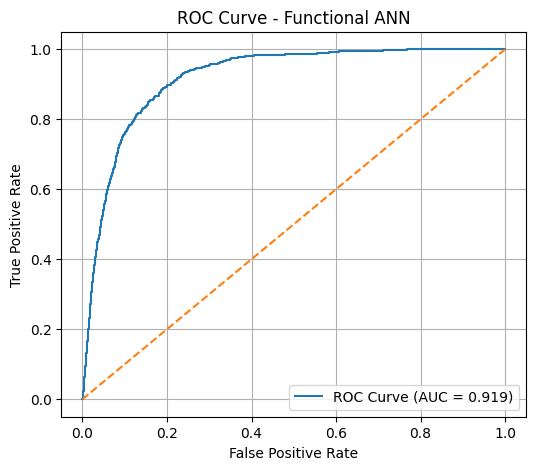

In [ ]:
# probability prediction
y_prob = functional_model.predict(X_test_processed).ravel()

# hitung ROC
fpr, tpr, thresholds = roc_curve(y_test_np, y_prob)
roc_auc = auc(fpr, tpr)

# plot ROC
plt.figure(figsize=(6,5))

plt.plot(fpr, tpr, label=f'ROC Curve (AUC = {roc_auc:.3f})')
plt.plot([0,1], [0,1], linestyle='--')

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve - Functional ANN")

plt.legend()
plt.grid()
plt.show()

### Analisis ROC Curve Functional ANN

Berdasarkan grafik ROC Curve, model Functional ANN memperoleh nilai AUC sebesar sekitar 0.919. Nilai ini menunjukkan bahwa model memiliki kemampuan yang sangat baik dalam membedakan antara kelas positif dan kelas negatif.

Kurva ROC terlihat melengkung mendekati sudut kiri atas grafik, yang menandakan bahwa model mampu mencapai True Positive Rate yang tinggi dengan tingkat False Positive Rate yang relatif rendah. Hal ini menunjukkan bahwa model cukup efektif dalam mengidentifikasi kasus positif tanpa terlalu banyak menghasilkan kesalahan prediksi.

Jika dibandingkan dengan garis diagonal (baseline model acak), kurva ROC model berada jauh di atas garis tersebut. Hal ini menunjukkan bahwa performa model jauh lebih baik dibandingkan dengan model yang melakukan prediksi secara acak.

Secara keseluruhan, nilai AUC yang tinggi mengindikasikan bahwa model memiliki kemampuan diskriminasi yang kuat dan cukup andal untuk digunakan dalam membedakan pelanggan yang berpotensi melakukan repeat dan yang tidak.

# PERBANDINGAN AKHIR KEDUA MODEL

In [342]:
results_df = pd.DataFrame([seq_results, func_results])
results_df

,model_name,loss,accuracy,precision,recall,f1_score,roc_auc
0,Sequential ANN,0.348217,0.840755,0.411035,0.836066,0.551122,0.915079
1,Functional ANN,0.344654,0.838101,0.408188,0.854981,0.552567,0.918852


Berdasarkan hasil evaluasi pada data test, kedua model yaitu **Sequential ANN** dan **Functional ANN** menunjukkan performa yang relatif mirip. Hal ini dapat dilihat dari nilai accuracy, loss, dan metrik evaluasi lainnya yang tidak memiliki perbedaan yang terlalu signifikan.

Model **Sequential ANN** memperoleh accuracy sebesar **0.8408**, sedangkan **Functional ANN** memperoleh accuracy sebesar **0.8381**. Perbedaan ini sangat kecil sehingga secara umum kedua model memiliki kemampuan prediksi yang hampir sama dalam mengklasifikasikan data.

Jika dilihat dari nilai **loss**, Functional ANN memiliki nilai loss yang sedikit lebih rendah (**0.3447**) dibandingkan Sequential ANN (**0.3482**). Nilai loss yang lebih kecil menunjukkan bahwa model Functional sedikit lebih baik dalam meminimalkan kesalahan prediksi selama proses evaluasi.

Pada metrik **precision**, kedua model memiliki nilai yang hampir sama yaitu sekitar **0.41**, yang menunjukkan bahwa dari seluruh prediksi positif yang dihasilkan oleh model, sekitar 41% merupakan prediksi yang benar. Hal ini menunjukkan bahwa kedua model masih menghasilkan cukup banyak false positive.

Namun pada metrik **recall**, Functional ANN memiliki nilai yang sedikit lebih tinggi (**0.8550**) dibandingkan Sequential ANN (**0.8361**). Hal ini menunjukkan bahwa Functional ANN lebih baik dalam mendeteksi kasus positif sehingga lebih sedikit data positif yang terlewat.

Hal yang sama juga terlihat pada nilai **ROC-AUC**, di mana Functional ANN memperoleh nilai **0.9189**, sedikit lebih tinggi dibandingkan Sequential ANN yang memperoleh **0.9151**. Nilai ROC-AUC yang tinggi menunjukkan bahwa kedua model memiliki kemampuan yang baik dalam membedakan antara kelas positif dan negatif.

Secara keseluruhan, kedua model menunjukkan performa yang sangat mirip. Namun, **Functional ANN sedikit lebih unggul** karena memiliki nilai **loss yang lebih rendah, recall yang lebih tinggi, serta ROC-AUC yang sedikit lebih baik**, sehingga model ini dapat dianggap memiliki kemampuan klasifikasi yang sedikit lebih baik dalam mendeteksi kasus positif.